**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Clase 20 - Aplicaciones económicas: una decisión, seis miradas**

*Una tienda online, un depósito automatizado y mil futuros posibles*

---

## El caso: la tienda online *Nodo Market*

**Nodo Market** es un ecommerce que vende por su **sitio web** y por su **app**. Tiene tres categorías: **accesorios** (fundas, cables, cargadores), **hogar** y **electrónica**. Hoy despacha todo con un operador logístico. Lucía, la dueña, tiene que decidir si invierte en un **depósito propio automatizado** (picking asistido y embalaje automático):

- Cuesta **\$ 9 millones**.
- Esperamos que deje **\$ 3,2 / 3,4 / 3,3 / 3 / 2,3 millones** por año durante cinco años (menores costos logísticos y más pedidos entregados el mismo día).
- Para pagarlo, Lucía pondría **\$ 3,5 millones propios** y necesitaría **\$ 5,5 millones de préstamo**: tiene tres ofertas y hay que elegir (es el primer dilema, Parte A).

> Ni el negocio ni los números son los de las clases 14 y 19 (allá el proyecto era un horno de panadería): acá cambian el negocio *y* la matemática, así que hay que volver a hacer las cuentas.

Esa es *una* decisión, pero para tomarla bien hay que mirarla de **seis maneras distintas** (y, antes de decidir, auditar nuestros propios números):

| Parte | La pregunta | De qué clase viene | Herramientas |
|---|---|---|---|
| **A** | ¿Qué préstamo conviene y cuánto cuesta la plata? | Clase 13 | TEM, IVA y comisiones, CFTEA, cuota, WACC, Fisher |
| **B** | ¿El depósito rinde? | Clase 14 | VAN, TIR, payback, IR, ROI |
| **C** | ¿Qué dicen los datos de ventas? | Clase 15.5 | pandas: limpieza, `groupby`, `merge`, regresión |
| **D** | ¿Llega la plata a fin de mes? | Clase 15 | flujo de caja, DSO / DPO / CCC, mora, semáforo |
| **E** | ¿Cuánto producir y cuánto vale lo acumulado? | Clase 16 | integrales: de lo marginal a lo acumulado |
| **F** | ¿Cuánto riesgo hay? | Clase 19 | muestreo, simulación de Monte Carlo |
| **G** | ¿Nos estamos mintiendo con los datos? | Clase "Cómo mentir con datos" | ventanas, porcentajes, correlación vs. causa, ejes y acumulados |
| **H** | La decisión | Todas | tablero final |

> **Ficticio, pero lógico.** Los datos de Nodo Market los inventamos nosotros (como en la clase 19), pero con reglas que tengan sentido. Una decisión vale lo que valen sus supuestos: vamos a ir marcando cuáles son.

Empezamos importando las librerías. Son las de siempre, más `sympy` (cuentas simbólicas, clase 16), `scipy` (para encontrar la TIR) y `sklearn` (regresión, clase 15.5). Definimos también dos funciones chiquitas para **mostrar pesos con puntos de miles**, como se escribe en Argentina.

In [1]:
import numpy as np                       # números y cuentas
import pandas as pd                      # tablas (DataFrames)
import matplotlib.pyplot as plt          # gráficos
import seaborn as sns                    # gráficos más lindos (clase 15.5)
import sympy as sp                       # cuentas simbólicas: derivadas e integrales (clase 16)
from scipy.optimize import brentq        # encuentra dónde una función vale cero (lo usamos para la TIR)
from sklearn.linear_model import LinearRegression   # regresión lineal (clase 15.5)

# Los colores de la cátedra para los gráficos
AZUL, NARANJA, ROJO, VERDE = "#243b5e", "#e07b39", "#b03a2e", "#2e8b57"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)

# numpy cambió el nombre de la regla del trapecio en la versión 2.0; esta línea funciona con las dos
trapecio = getattr(np, "trapezoid", None) or np.trapz

# Para mostrar plata: 1234567 -> "$ 1.234.567" (Python usa comas; acá usamos puntos)
def pesos(x):
    return "$ " + f"{x:,.0f}".replace(",", ".")

# Para mostrar millones: 3500000 -> "$ 3,50 M"
def millones(x):
    return "$ " + f"{x / 1e6:,.2f}".replace(".", ",") + " M"

---
# A. ¿Cuánta plata hace falta y cuánto cuesta? (clase 13)

Antes de evaluar el depósito hay que **financiarlo**, y ahí aparece el primer dilema de Lucía. Pone \$ 3,5 M propios, pero le faltan **\$ 5,5 M**, a devolver en **12 cuotas mensuales**. Le llegaron **tres ofertas**:

| | Banco Norte | Banco Sur | Línea Pyme provincial |
|---|---|---|---|
| **TNA** | 30,0% | 31,6% | 36,0% |
| **Capitalización** | mensual | mensual | mensual |
| **IVA sobre intereses** | 21% | 21% | exenta |
| **Seguro de vida mensual** (sobre saldo) | 0,25% | 0,10% | 0,10% |
| **Comisión mensual** | 0,60% | 0,15% | 0,50% |

El Banco Norte tiene **la TNA más baja**. ¿Es el más barato? Para saberlo hay que mirar **todo lo que se paga**, como en el último ejercicio de la clase 13:

1. **TEM básica** $= TNA/12$ (la TNA es nominal y capitaliza todos los meses).
2. **TEM con IVA** $=$ TEM básica $\times (1 + IVA)$.
3. **TEM total** $=$ TEM con IVA $+$ seguro $+$ comisión.
4. **TEA** (solo intereses) y **CFTEA** (costo financiero total efectivo anual): la TEM total capitalizada 12 meses.

> El IVA sobre intereses no siempre es un costo (una empresa puede computarlo como crédito fiscal), pero acá lo tratamos como costo, igual que en la clase 13.

In [2]:
PRESTAMO, N_CUOTAS = 5_500_000, 12        # lo que le falta a Lucía, y en cuántos meses lo devuelve

# Las tres ofertas, una fila por banco. Los porcentajes están en decimales (0.30 = 30%)
ofertas = pd.DataFrame({
    "TNA":              [0.300, 0.316, 0.360],
    "IVA":              [0.21,  0.21,  0.00],
    "Seguro mensual":   [0.0025, 0.0010, 0.0010],
    "Comisión mensual": [0.0060, 0.0015, 0.0050],
}, index=["Banco Norte", "Banco Sur", "Línea Pyme"])

# Los cuatro pasos, aplicados a las tres filas a la vez (pandas hace la cuenta fila por fila)
ofertas["TEM básica"]  = ofertas["TNA"] / 12
ofertas["TEM con IVA"] = ofertas["TEM básica"] * (1 + ofertas["IVA"])
ofertas["TEM total"]   = ofertas["TEM con IVA"] + ofertas["Seguro mensual"] + ofertas["Comisión mensual"]
ofertas["TEA"]         = (1 + ofertas["TEM básica"]) ** 12 - 1       # solo los intereses
ofertas["CFTEA"]       = (1 + ofertas["TEM total"]) ** 12 - 1        # todo lo que se paga

# .style.format le pone formato de porcentaje a la tabla (no cambia los números)
ofertas[["TNA", "TEM básica", "TEM con IVA", "TEM total", "TEA", "CFTEA"]].style.format("{:.2%}")

,TNA,TEM básica,TEM con IVA,TEM total,TEA,CFTEA
Banco Norte,30.00%,2.50%,3.02%,3.87%,34.49%,57.81%
Banco Sur,31.60%,2.63%,3.19%,3.44%,36.60%,50.00%
Línea Pyme,36.00%,3.00%,3.00%,3.60%,42.58%,52.87%


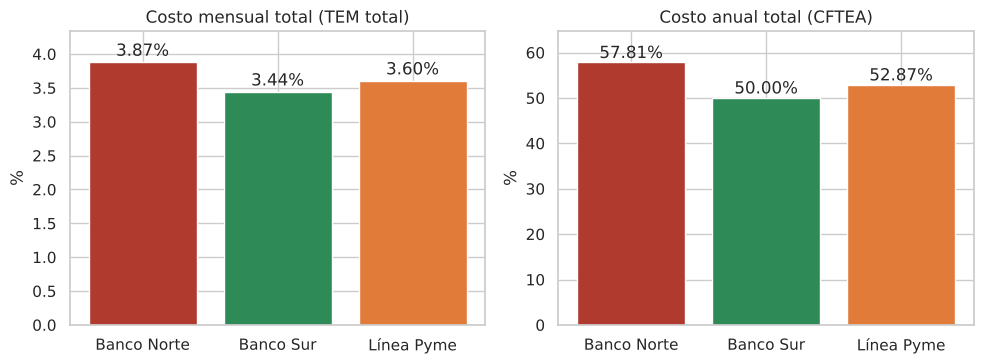

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, columna, titulo in [(axs[0], "TEM total", "Costo mensual total (TEM total)"), (axs[1], "CFTEA", "Costo anual total (CFTEA)")]:
    ax.bar(ofertas.index, ofertas[columna] * 100, color=[ROJO, VERDE, NARANJA])
    for i, v in enumerate(ofertas[columna]):
        ax.text(i, v * 100 + 0.1 * (1 if columna == "TEM total" else 10), f"{v:.2%}", ha="center")     # el valor arriba de cada barra
    ax.set_title(titulo)
    ax.set_ylabel("%")
    ax.set_ylim(top=ofertas[columna].max() * 100 * 1.12)     # un poco de aire arriba para los números
plt.tight_layout()
plt.show()

**Cómo se lee:** el Banco Norte, el de la **TNA más baja**, es el **más caro** (CFTEA ≈ 58%): el seguro y la comisión se comen la ventaja. La Línea Pyme está exenta de IVA, pero su TNA es tan alta que igual sale más cara que el Banco Sur. **Gana el Banco Sur, con un CFTEA de 50%.** Moraleja: *la TNA más baja no siempre gana*. Hay que comparar el **costo total**.

### A2. ¿Cuánto paga por mes? La cuota, sin fórmula complicada

En un préstamo con **cuotas iguales** (sistema francés) hay una sola idea, la de la clase 13: **lo que recibís hoy es igual al valor presente de todas las cuotas**.

$$P = cuota \times \left[\frac{1}{(1+i)^1} + \frac{1}{(1+i)^2} + \dots + \frac{1}{(1+i)^n}\right]$$

Entonces la cuota se despeja dividiendo: **cuota $= P \,/\,$ (suma de los factores de descuento)**. Es el mismo descuento que ya usamos para el VAN, sin memorizar ninguna fórmula nueva. (En Excel es `=PAGO(tasa; n; -P)`, y en Python existe `npf.pmt` de la librería `numpy-financial`; todas dan lo mismo.)

Usamos la **TEM total** como tasa mensual "todo incluido", para que los cargos queden dentro de la cuota.

In [4]:
def cuota_francesa(prestamo, tasa, n):
    factores = (1 + tasa) ** -np.arange(1, n + 1)     # cuánto vale hoy $ 1 que se cobra en el mes 1, 2, ..., n
    return prestamo / factores.sum()                   # el préstamo es el valor presente de las cuotas: se despeja la cuota

# La cuota y el costo total en pesos de cada oferta
ofertas["Cuota mensual"] = [cuota_francesa(PRESTAMO, t, N_CUOTAS) for t in ofertas["TEM total"]]
ofertas["Pesos de más"] = ofertas["Cuota mensual"] * N_CUOTAS - PRESTAMO        # lo que se paga por encima de los $ 5,5 M

for banco, fila in ofertas.iterrows():
    print(f"{banco:12s}: cuota {pesos(fila['Cuota mensual'])} por mes | paga {pesos(fila['Pesos de más'])} de más")

# Nos quedamos con la oferta de menor CFTEA
elegida = ofertas["CFTEA"].idxmin()
cuota = ofertas.loc[elegida, "Cuota mensual"]                 # esta cuota se usa en la Parte D
tem_correcta = ofertas.loc[elegida, "TEM total"]
print(f"\nElegimos: {elegida} (CFTEA {ofertas.loc[elegida, 'CFTEA']:.1%}), cuota de {pesos(cuota)}")

# Comprobación: el valor presente de las 12 cuotas tiene que dar exactamente los $ 5,5 M
print("Valor presente de las cuotas:", pesos((cuota * (1 + tem_correcta) ** -np.arange(1, N_CUOTAS + 1)).sum()))

Banco Norte : cuota $ 581.794 por mes | paga $ 1.481.533 de más
Banco Sur   : cuota $ 567.031 por mes | paga $ 1.304.374 de más
Línea Pyme  : cuota $ 572.516 por mes | paga $ 1.370.198 de más

Elegimos: Banco Sur (CFTEA 50.0%), cuota de $ 567.031
Valor presente de las cuotas: $ 5.500.000


### A3. Proporción vs. equivalencia: el error de "dividir por 12"

El Banco Sur cuesta **50% efectivo anual** (CFTEA). ¿Y por mes? El error más común es dividir por 12. Comparamos la forma incorrecta (proporción) con la correcta (equivalencia):

In [5]:
# Las dos funciones de la clase 13
def proporcion(tna, dias):
    return tna * dias / 365                    # solo es válida para tasas NOMINALES

def equivalencia(i, t2, t1):
    return (1 + i) ** (t2 / t1) - 1            # pasa una tasa EFECTIVA de un plazo (t1) a otro (t2)

CFTEA = 0.50                                   # el CFTEA del Banco Sur, redondeado

tem_ingenua  = CFTEA / 12                      # lo que sale si "dividimos por 12" (incorrecto)
tem_equiv = equivalencia(CFTEA, 1, 12)         # tasa efectiva de 1 mes (1/12 de año) equivalente a 50% anual

print(f"Dividiendo por 12 (mal)  : {tem_ingenua:.2%} por mes")
print(f"Con equivalencia (bien)  : {tem_equiv:.2%} por mes   <- es la TEM total del Banco Sur")

# Comprobación: si el interés mensual correcto se capitaliza 12 veces, tiene que volver a dar 50%
print(f"Capitalizando 12 meses   : {(1 + tem_equiv) ** 12 - 1:.2%}  <- vuelve al 50%")
print(f"Con la tasa 'ingenua'    : {(1 + tem_ingenua) ** 12 - 1:.2%}  <- ¡no es el 50% que cobra el banco!")

Dividiendo por 12 (mal)  : 4.17% por mes
Con equivalencia (bien)  : 3.44% por mes   <- es la TEM total del Banco Sur
Capitalizando 12 meses   : 50.00%  <- vuelve al 50%
Con la tasa 'ingenua'    : 63.21%  <- ¡no es el 50% que cobra el banco!


### A4. El costo del capital del depósito (WACC) y la tasa real

Los **\$ 3,5 M propios** tienen un costo (los socios esperan un rendimiento del **65%** anual en pesos) y los **\$ 5,5 M del banco** también: el **CFTEA del Banco Sur, 50%**. Pero los intereses se descuentan de Ganancias (30%): es el **escudo fiscal**. El **WACC** es el promedio ponderado de los dos costos.

Después lo pasamos a **tasa real** con la fórmula de Fisher, suponiendo una inflación esperada del **22,5% anual**.

In [6]:
# Datos del financiamiento (los mismos de la clase 13)
capital_propio, deuda = 3_500_000, PRESTAMO
ke, kd, impuesto = 0.65, round(ofertas.loc[elegida, "CFTEA"], 2), 0.30      # costo del capital propio, costo de la deuda (CFTEA elegido), Ganancias

we = capital_propio / (capital_propio + deuda)   # peso del capital propio en el total
wd = deuda / (capital_propio + deuda)            # peso de la deuda

kd_neto = kd * (1 - impuesto)                    # la deuda cuesta menos porque los intereses se deducen
wacc_nominal = we * ke + wd * kd_neto            # promedio ponderado: el WACC en pesos corrientes

# Fisher: 1 + i_real = (1 + i_nominal) / (1 + inflación)
INFLACION_ANUAL = 0.225                          # supuesto de la clase: inflación esperada de 22,5% anual
fisher = lambda i_nominal: (1 + i_nominal) / (1 + INFLACION_ANUAL) - 1

wacc_real = fisher(wacc_nominal)

print(f"Costo de la deuda (CFTEA)             : {kd:.1%}")
print(f"Costo de la deuda después de impuestos: {kd_neto:.1%}")
print(f"WACC nominal (pesos corrientes)       : {wacc_nominal:.1%}")
print(f"WACC REAL                             : {wacc_real:.1%}")

Costo de la deuda (CFTEA)             : 50.0%
Costo de la deuda después de impuestos: 35.0%
WACC nominal (pesos corrientes)       : 46.7%
WACC REAL                             : 19.7%


Por eso para el depósito usamos **19,7%**: los flujos del depósito están en **pesos de hoy** (constantes), y entonces hay que descontarlos con una tasa **real**. Si mezcláramos flujos en pesos de hoy con una tasa de 47%, el depósito parecería un desastre sin serlo.

> **Regla:** pesos corrientes ↔ tasa nominal; pesos constantes ↔ tasa real. Nunca mezclar.

---
# B. ¿El depósito rinde? (clase 14)

Con el costo de capital real (**19,7%**) evaluamos el depósito con las métricas de la clase 14. Cada una responde una pregunta distinta:

| Métrica | Pregunta | Regla |
|---|---|---|
| **VAN** | ¿Cuánta riqueza crea, en pesos de hoy? | conviene si $>0$ |
| **TIR** | ¿Cuánto rinde por año? | conviene si $>$ costo de capital |
| **Payback** | ¿En cuánto tiempo recupero la plata? | cuanto antes, mejor (el *descontado* es el serio) |
| **IR** | ¿Cuánto valor creo por cada peso invertido? | conviene si $>1$ |
| **ROI** | ¿Cuánto gano sobre lo que puse? | **no mira el tiempo** (trampa) |

Armamos las funciones una sola vez y las aplicamos al depósito:

In [7]:
R = wacc_real                                     # costo de capital real que calculamos en la Parte A (19,7%)

# Flujos del depósito en pesos de hoy: el año 0 es la inversión (negativa), los años 1 a 5 son los cobros
flujos = np.array([-9_000_000, 3_200_000, 3_400_000, 3_300_000, 3_000_000, 2_300_000])
años = np.arange(len(flujos))                     # 0, 1, 2, 3, 4, 5

def van(flujos, tasa):
    # cada flujo se divide por (1+tasa) elevado a su año, y se suman todos
    return (flujos / (1 + tasa) ** np.arange(len(flujos))).sum()

def tir(flujos):
    # la TIR es la tasa que hace VAN = 0; brentq la busca entre -90% y 1000%
    return brentq(lambda tasa: van(flujos, tasa), -0.9, 10)

def payback(flujos):
    # años hasta recuperar la inversión, interpolando dentro del año; None si nunca se recupera
    acumulado = flujos[0]
    for año in range(1, len(flujos)):
        if acumulado + flujos[año] >= 0:
            return (año - 1) + (-acumulado) / flujos[año]
        acumulado += flujos[año]
    return None

inversion = -flujos[0]
vp = flujos / (1 + R) ** años                     # valor presente de cada flujo

metricas = pd.DataFrame({
    "Métrica": ["VAN", "TIR", "Payback simple", "Payback descontado", "IR", "ROI"],
    "Resultado": [millones(van(flujos, R)), f"{tir(flujos):.1%}", f"{payback(flujos):.2f} años",
                  f"{payback(vp):.2f} años", f"{vp[1:].sum() / inversion:.3f}", f"{flujos[1:].sum() / inversion - 1:.0%}"],
    "¿Qué dice?": ["> 0: crea valor", f"> {R:.1%}: rinde más que su costo", "se recupera en menos de 3 años",
                   "se recupera, pero sobre el final (vida útil: 5 años)", "> 1: crea valor, por poco",
                   "suena a mucho, pero ignora CUÁNDO se cobra"],
})
metricas

,Métrica,Resultado,¿Qué dice?
0,VAN,"$ 0,36 M",> 0: crea valor
1,TIR,21.6%,> 19.7%: rinde más que su costo
2,Payback simple,2.73 años,se recupera en menos de 3 años
3,Payback descontado,4.61 años,"se recupera, pero sobre el final (vida útil: 5..."
4,IR,1.040,"> 1: crea valor, por poco"
5,ROI,69%,"suena a mucho, pero ignora CUÁNDO se cobra"


Las métricas **no dicen lo mismo**. El ROI da 69% y suena espectacular, pero lo que cobrás en el año 5 no vale lo mismo que lo que cobrás en el año 1. El VAN, la TIR y el IR *sí* descuentan el tiempo, y coinciden: el depósito **conviene, pero por poco** (un IR de 1,04 quiere decir 4 centavos de valor por cada peso invertido).

Lo vemos en un gráfico: cuándo se recupera la inversión, sin descontar y descontando.

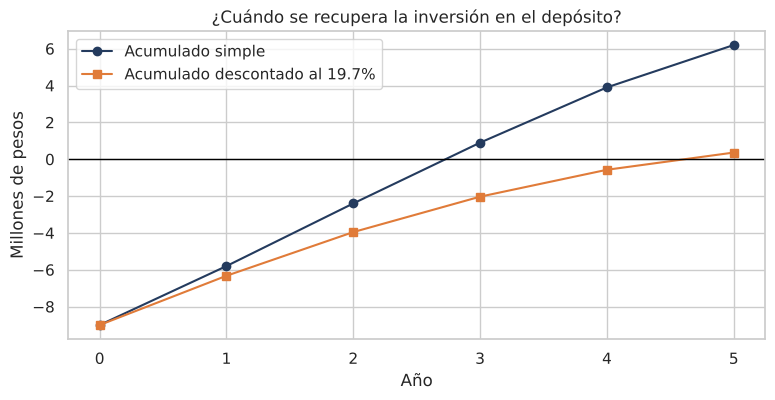

In [8]:
acumulado_simple = flujos.cumsum()                # plata acumulada, sin descontar
acumulado_desc = vp.cumsum()                      # plata acumulada, en pesos de hoy

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(años, acumulado_simple / 1e6, "o-", color=AZUL, label="Acumulado simple")
ax.plot(años, acumulado_desc / 1e6, "s-", color=NARANJA, label=f"Acumulado descontado al {R:.1%}")
ax.axhline(0, color="black", lw=1)                # donde cruza el cero se recupera la inversión
ax.set_xlabel("Año")
ax.set_ylabel("Millones de pesos")
ax.set_title("¿Cuándo se recupera la inversión en el depósito?")
ax.legend()
plt.show()

**Cómo se lee:** las dos curvas arrancan en $-9$ M. La azul cruza el cero a los 2,7 años. La naranja (que descuenta) recién lo hace a los 4,6, con la vida útil casi terminada, y termina apenas arriba del cero. Descontar el tiempo **achica** el negocio, y eso es lo que hace que el VAN sea chico (+0,36 M).


**Por qué se comparan**

Si la TIR supera al WACC, los flujos del proyecto alcanzan para devolverle al banco y a los socios lo que exigen, y encima sobra. Ese sobrante, medido en pesos de hoy, es justamente el VAN. Por eso las dos reglas dicen lo mismo:

- TIR > WACC ⇔ VAN descontado al WACC > 0.
- En el caso: 21,6% > 19,7% ⇔ VAN = +\$ 0,36 M.


### ¿Por qué la TIR no alcanza sola? La comparación con el costo de cada fuente

La TIR (≈22%) le gana al WACC real (≈19,7%). Pero **no todas las fuentes de plata cuestan lo mismo**. Comparamos, todo en términos **reales**:

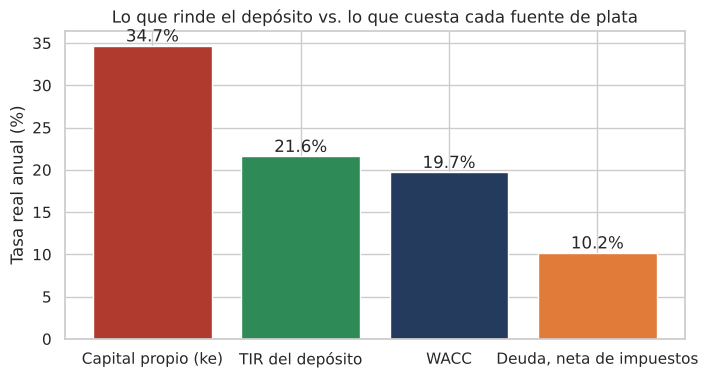

In [9]:
tir_deposito = tir(flujos)

# Pasamos a términos reales cada costo, con Fisher (la función 'fisher' de la Parte A)
costos = pd.Series({
    "Capital propio (ke)": fisher(ke),
    "TIR del depósito": tir_deposito,
    "WACC": wacc_real,
    "Deuda, neta de impuestos": fisher(kd_neto),
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(costos.index, costos.values * 100, color=[ROJO, VERDE, AZUL, NARANJA])
for i, v in enumerate(costos.values):
    ax.text(i, v * 100 + 0.5, f"{v:.1%}", ha="center")       # el valor arriba de cada barra
ax.set_ylabel("Tasa real anual (%)")
ax.set_title("Lo que rinde el depósito vs. lo que cuesta cada fuente de plata")
plt.show()

**Cómo se lee:** el depósito rinde ≈22% real. Es **menos** de lo que esperan los socios (≈35% real), pero **más** de lo que cuesta la deuda después de impuestos (≈10% real), y el WACC (19,7%) es el promedio ponderado de los dos. Por eso el proyecto "pasa" solo con la mezcla de financiamiento de Lucía: cuanta más deuda barata, más fácil es que el depósito convenga.

Esto es **apalancamiento**. Lo vimos con el ROE en la clase 14 y lo vamos a retomar en la Parte D (qué pasa con la caja si se financia).

---
# C. ¿Qué dicen los datos de ventas? (clase 15.5)

Hasta acá todo fue "de escritorio". Ahora miramos **datos**: los pedidos diarios de Nodo Market durante 2025. En la vida real saldrían de la plataforma de ecommerce (una exportación de pedidos en CSV); acá los fabricamos con las técnicas de la clase 19 (semilla, `rng.normal`, etc.). No hace falta entender esa celda ahora: lo que importa es **lo que viene después**.

> **Datos con problemas, a propósito.** Los datos reales vienen sucios, así que a la base le "ensuciamos" tres cosas: hay **nulos**, **filas duplicadas** y **un error de tipeo**. Hay que encontrarlos y arreglarlos antes de analizar.

In [10]:
rng = np.random.default_rng(2025)                       # semilla: todos obtenemos los mismos datos

fechas = pd.date_range("2025-01-01", "2025-12-31")      # los 365 días del año
dia_del_año = fechas.dayofyear.values

# Inversión diaria en publicidad (miles de pesos): más alta hacia Black Friday y Cyber Monday (fines de noviembre), más variación diaria
publicidad = 20 + 6 * np.cos(2 * np.pi * (dia_del_año - 330) / 365) + rng.normal(0, 3, len(fechas))

# Se vende más los fines de semana (un factor por día: lunes a domingo)
factor_dia = np.array([0.92, 0.92, 0.95, 0.97, 1.03, 1.12, 1.09])[fechas.dayofweek]
# Hogar y electrónica tienen estacionalidad: Hot Sale (mayo), Black Friday y Cyber Monday (noviembre), fiestas (diciembre)
factor_mes = np.array([0.90, 0.85, 0.95, 1.0, 1.05, 1.0, 1.0, 1.0, 1.0, 1.05, 1.25, 1.30])[fechas.month - 1]

tablas = []
for canal, peso in [("Web", 0.6), ("App", 0.4)]:                 # la web vende el 60%
    # Accesorios: ~120 unidades por día en total; más cuando se invierte más en publicidad (por cada \$ 1.000 sobre 20.000, +1,5 unidades)
    accesorios = 120 * factor_dia * peso + 1.5 * (publicidad - 20) * peso + rng.normal(0, 9 * np.sqrt(peso), len(fechas))
    # Hogar: ~60 unidades por día
    hogar = 60 * factor_dia * factor_mes * peso + rng.normal(0, 6 * np.sqrt(peso), len(fechas))
    # Electrónica: pocas unidades por día, más los fines de semana (Poisson = conteo de cosas raras)
    electronica = rng.poisson(8 * factor_dia ** 2 * factor_mes * peso)
    for producto, cantidad in [("Accesorios", accesorios), ("Hogar", hogar), ("Electrónica", electronica)]:
        tablas.append(pd.DataFrame({"fecha": fechas, "canal": canal, "producto": producto,
                                    "cantidad": np.round(cantidad).clip(0), "publicidad": publicidad.round(1)}))

ventas = pd.concat(tablas, ignore_index=True)           # pegamos las seis tablas (2 canales x 3 categorías)

# --- Ensuciamos la base, como pasa en la realidad ---
ventas.loc[rng.choice(len(ventas), size=40, replace=False), "cantidad"] = np.nan   # 40 cantidades que no se cargaron
fila_error = ventas[(ventas["producto"] == "Accesorios") & (ventas["canal"] == "Web")].index[100]
ventas.loc[fila_error, "cantidad"] = 1080               # error de tipeo: debía ser ~108, se escribió 1080
ventas = pd.concat([ventas, ventas.sample(15, random_state=1)])   # 15 filas cargadas dos veces (por ejemplo, un pedido reenviado)
ventas = ventas.sort_values(["fecha", "canal", "producto"]).reset_index(drop=True)

# La tabla de precios y costos de cada categoría (viene de otro lado: otra tabla).
# 'costo' = costo variable total por unidad (mercadería + preparación + envío)
productos = pd.DataFrame({"producto": ["Accesorios", "Hogar", "Electrónica"],
                          "precio": [500, 3_200, 18_000], "costo": [200, 1_400, 9_000]})
productos

,producto,precio,costo
0,Accesorios,500,200
1,Hogar,3200,1400
2,Electrónica,18000,9000


### C1. Primer vistazo: estructura y calidad (punto 3.1 del TP)

Lo primero siempre es **mirar**: cuántas filas y columnas hay, de qué tipo es cada una, y las primeras y últimas filas.

In [11]:
print("Dimensiones (filas, columnas):", ventas.shape)
print("\nTipos de dato:")
print(ventas.dtypes)
ventas.head()

Dimensiones (filas, columnas): (2205, 5)

Tipos de dato:
fecha         datetime64[us]
canal                    str
producto                 str
cantidad             float64
publicidad           float64
dtype: object


,fecha,canal,producto,cantidad,publicidad
0,2025-01-01,App,Accesorios,40.0,18.2
1,2025-01-01,App,Electrónica,4.0,18.2
2,2025-01-01,App,Hogar,23.0,18.2
3,2025-01-01,Web,Accesorios,62.0,18.2
4,2025-01-01,Web,Electrónica,5.0,18.2


In [12]:
ventas.tail()      # las últimas cinco filas: ¿terminan donde esperamos? (31 de diciembre)

,fecha,canal,producto,cantidad,publicidad
2200,2025-12-31,App,Electrónica,5.0,19.7
2201,2025-12-31,App,Hogar,33.0,19.7
2202,2025-12-31,Web,Accesorios,67.0,19.7
2203,2025-12-31,Web,Electrónica,5.0,19.7
2204,2025-12-31,Web,Hogar,48.0,19.7


Ahora la **calidad**: ¿cuántos nulos y cuántos duplicados hay? Y con `describe()` por producto buscamos valores raros (un máximo que no tiene sentido).

In [13]:
print("Nulos por columna:")
print(ventas.isnull().sum())                                 # isnull() marca cada celda vacía; sum() las cuenta por columna
print("\nFilas duplicadas:", ventas.duplicated().sum())      # duplicated() marca las filas idénticas a otra anterior

# Estadísticas por producto: fijate en el máximo de los accesorios
ventas.groupby("producto")["cantidad"].describe()

Nulos por columna:
fecha          0
canal          0
producto       0
cantidad      40
publicidad     0
dtype: int64

Filas duplicadas: 15


,count,mean,std,min,25%,50%,75%,max
producto,,,,,,,,
Accesorios,729.0,61.536351,40.597449,26.0,48.0,59.0,73.0,1080.0
Electrónica,718.0,4.316156,2.388149,0.0,3.0,4.0,6.0,14.0
Hogar,718.0,30.690808,8.567181,13.0,24.0,30.0,36.0,60.0


**Hallazgos:**
- **40 nulos** en `cantidad`: no se cargó la venta.
- **15 duplicados**: la misma venta cargada dos veces (inflaría las ventas).
- **Un valor imposible**: el máximo de accesorios es **1.080** unidades en un canal en un día, cuando lo normal es menos de 100. Es un error de tipeo (le sobra un cero).

### C2. Limpieza: tres transformaciones justificadas (punto 3.3 del TP)

In [14]:
n_inicial = len(ventas)

# 1) Duplicados: si dos filas son idénticas, la venta se cargó dos veces. Dejamos una sola.
ventas = ventas.drop_duplicates().reset_index(drop=True)
print("Filas eliminadas por duplicadas:", n_inicial - len(ventas))

# 2) Valor imposible: lo marcamos como nulo (así lo trata igual que a los que faltan, en el paso 3)
imposibles = (ventas["producto"] == "Accesorios") & (ventas["cantidad"] > 500)   # ningún canal vende 500 accesorios en un día
print("Valores imposibles encontrados :", imposibles.sum())
ventas.loc[imposibles, "cantidad"] = np.nan

# 3) Nulos: no los borramos (perderíamos días enteros). Los completamos con la MEDIANA de su grupo
#    (mismo canal y misma categoría). transform("median") devuelve la mediana del grupo para cada fila.
mediana_grupo = ventas.groupby(["canal", "producto"])["cantidad"].transform("median")
ventas["cantidad"] = ventas["cantidad"].fillna(mediana_grupo)

print("Nulos que quedan               :", ventas["cantidad"].isnull().sum())

Filas eliminadas por duplicadas: 15
Valores imposibles encontrados : 1
Nulos que quedan               : 0


Elegimos la **mediana** y no el promedio porque no la mueven los valores extremos. Y completamos en vez de borrar porque cada fila borrada sería un día sin información. La contra: la mediana "aplana" ese día (no sabemos si fue de mucha o poca venta). Es una decisión con un costo, y hay que decirlo en el informe.

### C3. Unir tablas (`merge`) y crear columnas nuevas

Cada fila tiene la **cantidad**, pero el **precio** y el **costo** están en la otra tabla. Con `merge` las unimos por la columna `producto` (clase 15.5) y calculamos ingreso, costo y margen.

In [15]:
# merge: pega a cada fila de 'ventas' el precio y el costo de su producto
# how="left": conservamos TODAS las filas de ventas, aunque el producto no estuviera en la tabla de precios
ventas = ventas.merge(productos, on="producto", how="left")

ventas["ingreso"] = ventas["cantidad"] * ventas["precio"]     # lo que se cobra
ventas["cmv"] = ventas["cantidad"] * ventas["costo"]          # costo de la mercadería vendida
ventas["margen"] = ventas["ingreso"] - ventas["cmv"]          # lo que queda

# Columnas de fecha: mes (1 a 12) y si es fin de semana (sábado = 5, domingo = 6)
ventas["mes"] = ventas["fecha"].dt.month
ventas["fin_de_semana"] = (ventas["fecha"].dt.dayofweek >= 5).astype(int)    # 1 si es sábado o domingo, 0 si no

print("Productos sin precio (el merge no encontró):", ventas["precio"].isnull().sum())
ventas.head()

Productos sin precio (el merge no encontró): 0


,fecha,canal,producto,cantidad,publicidad,precio,costo,ingreso,cmv,margen,mes,fin_de_semana
0,2025-01-01,App,Accesorios,40.0,18.2,500,200,20000.0,8000.0,12000.0,1,0
1,2025-01-01,App,Electrónica,4.0,18.2,18000,9000,72000.0,36000.0,36000.0,1,0
2,2025-01-01,App,Hogar,23.0,18.2,3200,1400,73600.0,32200.0,41400.0,1,0
3,2025-01-01,Web,Accesorios,62.0,18.2,500,200,31000.0,12400.0,18600.0,1,0
4,2025-01-01,Web,Electrónica,5.0,18.2,18000,9000,90000.0,45000.0,45000.0,1,0


### C3b. Los tipos de `join`: ¿qué hago con las filas que no tienen pareja?

En C3 usamos `how="left"` sin explicar por qué. Un `merge` (en SQL se llama **join**) pega dos tablas por una **clave**, y la pregunta es siempre la misma: **¿qué pasa con las filas que no encuentran pareja en la otra tabla?** Cada tipo de join es una respuesta distinta. Para verlo usamos dos tablas chiquitas de Nodo Market, unidas por `id_cliente`:

- **A = `pedidos`**: lo que se compró. El pedido **P4** es de alguien que compró **sin registrarse**, así que su `id_cliente` no está en la otra tabla.
- **B = `clientes`**: la base de registrados. **Elena** se registró pero **nunca compró**.

Las filas de `id_cliente` 101, 102 y 103 están en las dos tablas: esas **sí tienen pareja**.

In [16]:
# A: los pedidos (el cliente 104 no está registrado)
pedidos = pd.DataFrame({"id_cliente": [101, 102, 103, 104],
                        "pedido":     ["P1", "P2", "P3", "P4"],
                        "monto":      [18_500, 42_000, 9_800, 27_300]})

# B: los clientes registrados (la 105, Elena, nunca compró)
clientes = pd.DataFrame({"id_cliente": [101, 102, 103, 105],
                         "nombre":     ["Ana", "Beto", "Caro", "Elena"],
                         "ciudad":     ["CABA", "Rosario", "Córdoba", "Mendoza"]})

print("A = pedidos");  display(pedidos)
print("B = clientes"); display(clientes)

A = pedidos


,id_cliente,pedido,monto
0,101,P1,18500
1,102,P2,42000
2,103,P3,9800
3,104,P4,27300


B = clientes


,id_cliente,nombre,ciudad
0,101,Ana,CABA
1,102,Beto,Rosario
2,103,Caro,Córdoba
3,105,Elena,Mendoza


Cada círculo es una tabla; la **intersección** son las filas que tienen pareja (la clave está en las dos). En **verde**, las filas que quedan en el resultado según el `how=` que elijas (los números salen de las tablas de arriba):

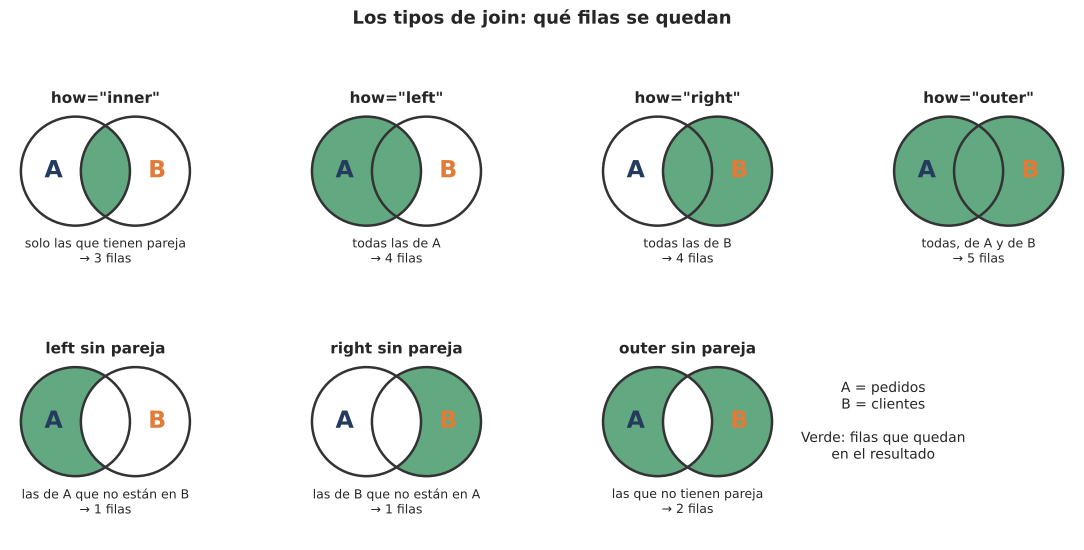

In [17]:
# INNER JOIN
inner = pedidos.merge(clientes, on="id_cliente", how="inner")

# LEFT JOIN
left = pedidos.merge(clientes, on="id_cliente", how="left")

# RIGHT JOIN
right = pedidos.merge(clientes, on="id_cliente", how="right")

# OUTER JOIN
outer = pedidos.merge(clientes, on="id_cliente", how="outer")

# Los 7 casos de join dibujados como diagramas de Venn (no hace falta entender el código del dibujo: lo que importa es la imagen)
m = pedidos.merge(clientes, on="id_cliente", how="outer", indicator=True)    # indicator=True agrega la columna _merge
n = m["_merge"].value_counts()                                               # cuántas filas hay de cada tipo
solo_A, ambas, solo_B = n["left_only"], n["both"], n["right_only"]

# (título, qué regiones quedan: A sola, intersección, B sola, cuántas filas, descripción)
casos = [('how="inner"',        (0, 1, 0), ambas,                   "solo las que tienen pareja"),
         ('how="left"',         (1, 1, 0), solo_A + ambas,          "todas las de A"),
         ('how="right"',        (0, 1, 1), ambas + solo_B,          "todas las de B"),
         ('how="outer"',        (1, 1, 1), solo_A + ambas + solo_B, "todas, de A y de B"),
         ('left sin pareja',    (1, 0, 0), solo_A,                  "las de A que no están en B"),
         ('right sin pareja',   (0, 0, 1), solo_B,                  "las de B que no están en A"),
         ('outer sin pareja',   (1, 0, 1), solo_A + solo_B,         "las que no tienen pareja")]

y, x = np.mgrid[-1.1:1.1:300j, -1.75:1.75:700j]                # una grilla de puntos para pintar
en_A, en_B = (x + 0.55) ** 2 + y ** 2 <= 1, (x - 0.55) ** 2 + y ** 2 <= 1
regiones = [en_A & ~en_B, en_A & en_B, en_B & ~en_A]           # A sola, intersección, B sola

fig, axs = plt.subplots(2, 4, figsize=(11, 5.6))
for ax, (titulo, quedan, filas, que) in zip(axs.flat, casos):
    pintar = np.zeros(x.shape, dtype=bool)
    for region, queda in zip(regiones, quedan):
        if queda:
            pintar |= region                                   # sumamos las regiones que se quedan
    imagen = np.zeros(x.shape + (4,))
    imagen[pintar] = plt.matplotlib.colors.to_rgba(VERDE, 0.75)
    ax.imshow(imagen, extent=(-1.75, 1.75, -1.1, 1.1), origin="lower")
    for cx in (-0.55, 0.55):
        ax.add_patch(plt.Circle((cx, 0), 1, fill=False, ec="#333333", lw=1.8))
    ax.text(-0.95, 0, "A", ha="center", va="center", fontsize=17, fontweight="bold", color=AZUL)
    ax.text(0.95, 0, "B", ha="center", va="center", fontsize=17, fontweight="bold", color=NARANJA)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_xlabel(f"{que}\n→ {filas} filas", fontsize=9)
    ax.set_xlim(-1.75, 1.75); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)

axs.flat[7].axis("off")                                        # el último casillero es la referencia
axs.flat[7].text(0, 0.5, "A = pedidos\nB = clientes\n\nVerde: filas que quedan\nen el resultado", ha="center", va="center", fontsize=10)
fig.suptitle("Los tipos de join: qué filas se quedan", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Ahora los mismos casos con las tablas de verdad. Mirá qué pasa con **P4** (pedido sin cliente registrado) y con **Elena** (cliente sin pedidos): según el `how=`, aparecen con `NaN` o desaparecen.

In [18]:
explicaciones = {
    "inner": "solo lo que tiene pareja: P4 y Elena desaparecen",
    "left":  "todos los pedidos; P4 queda con nombre y ciudad en NaN (no está registrado)",
    "right": "todos los clientes; Elena queda con pedido y monto en NaN (nunca compró)",
    "outer": "todo lo de las dos tablas: las filas sin pareja quedan con NaN del lado que falta",
}

for como, explicacion in explicaciones.items():
    print(f'how="{como}": {explicacion}')
    display(pedidos.merge(clientes, on="id_cliente", how=como))

how="inner": solo lo que tiene pareja: P4 y Elena desaparecen


,id_cliente,pedido,monto,nombre,ciudad
0,101,P1,18500,Ana,CABA
1,102,P2,42000,Beto,Rosario
2,103,P3,9800,Caro,Córdoba


how="left": todos los pedidos; P4 queda con nombre y ciudad en NaN (no está registrado)


,id_cliente,pedido,monto,nombre,ciudad
0,101,P1,18500,Ana,CABA
1,102,P2,42000,Beto,Rosario
2,103,P3,9800,Caro,Córdoba
3,104,P4,27300,NaN,NaN


how="right": todos los clientes; Elena queda con pedido y monto en NaN (nunca compró)


,id_cliente,pedido,monto,nombre,ciudad
0,101,P1,18500.0,Ana,CABA
1,102,P2,42000.0,Beto,Rosario
2,103,P3,9800.0,Caro,Córdoba
3,105,NaN,NaN,Elena,Mendoza


how="outer": todo lo de las dos tablas: las filas sin pareja quedan con NaN del lado que falta


,id_cliente,pedido,monto,nombre,ciudad
0,101,P1,18500.0,Ana,CABA
1,102,P2,42000.0,Beto,Rosario
2,103,P3,9800.0,Caro,Córdoba
3,104,P4,27300.0,NaN,NaN
4,105,NaN,NaN,Elena,Mendoza


**Los "sin pareja" (anti-join).** Para auditar datos muchas veces importa justamente lo que *no* coincide: ¿hay pedidos sin cliente?, ¿clientes que nunca compraron? `pandas` no tiene un `how="anti"`, pero se arma con `indicator=True`: la columna `_merge` dice de qué lado vino cada fila (`both`, `left_only` o `right_only`) y después se filtra.

In [19]:
m = pedidos.merge(clientes, on="id_cliente", how="outer", indicator=True)
print("Un outer con indicator=True: la columna _merge dice de dónde vino cada fila")
display(m)

print("left sin pareja: pedidos de clientes que no están registrados")
display(m[m["_merge"] == "left_only"][pedidos.columns])

print("right sin pareja: clientes registrados que nunca compraron")
display(m[m["_merge"] == "right_only"][clientes.columns])

print("outer sin pareja: todo lo que no coincide, de cualquiera de las dos")
display(m[m["_merge"] != "both"].drop(columns="_merge"))

Un outer con indicator=True: la columna _merge dice de dónde vino cada fila


,id_cliente,pedido,monto,nombre,ciudad,_merge
0,101,P1,18500.0,Ana,CABA,both
1,102,P2,42000.0,Beto,Rosario,both
2,103,P3,9800.0,Caro,Córdoba,both
3,104,P4,27300.0,NaN,NaN,left_only
4,105,NaN,NaN,Elena,Mendoza,right_only


left sin pareja: pedidos de clientes que no están registrados


,id_cliente,pedido,monto
3,104,P4,27300.0


right sin pareja: clientes registrados que nunca compraron


,id_cliente,nombre,ciudad
4,105,Elena,Mendoza


outer sin pareja: todo lo que no coincide, de cualquiera de las dos


,id_cliente,pedido,monto,nombre,ciudad
3,104,P4,27300.0,NaN,NaN
4,105,NaN,NaN,Elena,Mendoza


**Resumen: ¿qué `how=` uso?**

| Quiero quedarme con... | En pandas | En SQL | Ejemplo en Nodo Market |
|---|---|---|---|
| solo las filas con pareja en las dos tablas | `how="inner"` | `INNER JOIN` | pedidos de clientes registrados |
| todas las de A, con o sin pareja | `how="left"` | `LEFT JOIN` | todas las ventas, aunque falte el precio (C3) |
| todas las de B, con o sin pareja | `how="right"` | `RIGHT JOIN` | todos los clientes, hayan comprado o no |
| todas las de las dos tablas | `how="outer"` | `FULL OUTER JOIN` | el cruce completo, para revisarlo |
| las de A que no tienen pareja | `how="left"` + `indicator=True`, filtrar `left_only` | `LEFT JOIN ... WHERE B.clave IS NULL` | pedidos sin cliente registrado |
| las de B que no tienen pareja | `how="right"` + `indicator=True`, filtrar `right_only` | `RIGHT JOIN ... WHERE A.clave IS NULL` | clientes que nunca compraron |
| las que no tienen pareja, de cualquiera | `how="outer"` + `indicator=True`, filtrar `!= "both"` | `FULL OUTER JOIN ... WHERE A.clave IS NULL OR B.clave IS NULL` | auditoría de las dos tablas |

> **Regla práctica:** antes y después de cada `merge`, comparar la cantidad de filas (`len(...)`). Si cambió y no lo esperabas, el `how=` no era el que creías. En el Ejercicio 6 se ve cómo un `inner` hace desaparecer parte del negocio sin avisar.

### C4. Resumen estadístico por grupo (`groupby`)

¿Qué categoría y qué canal aportan más? Agrupamos y calculamos ingreso, margen y **margen porcentual**.

In [20]:
por_producto = ventas.groupby("producto").agg(ingreso=("ingreso", "sum"), margen=("margen", "sum"))
por_producto["margen_%"] = por_producto["margen"] / por_producto["ingreso"] * 100       # margen sobre ventas
por_producto["% del margen total"] = por_producto["margen"] / por_producto["margen"].sum() * 100
display(por_producto.round(1))

por_canal = ventas.groupby("canal").agg(ingreso=("ingreso", "sum"), margen=("margen", "sum"))
por_canal["% del ingreso"] = por_canal["ingreso"] / por_canal["ingreso"].sum() * 100
display(por_canal.round(1))

,ingreso,margen,margen_%,% del margen total
producto,,,,
Accesorios,21972000.0,13183200.0,60.0,16.1
Electrónica,56664000.0,28332000.0,50.0,34.6
Hogar,71696000.0,40329000.0,56.2,49.3


,ingreso,margen,% del ingreso
canal,,,
App,59944700.0,32652300.0,39.9
Web,90387300.0,49191900.0,60.1


**Interpretación:** los **accesorios** son los que mejor margen porcentual tienen (60%), pero pesan solo **~15% del ingreso** y **~16% del margen**: hogar y electrónica mueven la mayor parte de la plata. Esto importa para el depósito: si solo mejora el despacho de accesorios, no alcanza para justificar los \$ 3,2 millones por año (lo vamos a comprobar en la Parte E).

### C5. Tres gráficos de tipos distintos (punto 3.4 del TP)

**Gráfico 1. Comparación entre categorías:** ¿cuánto margen aporta cada producto?

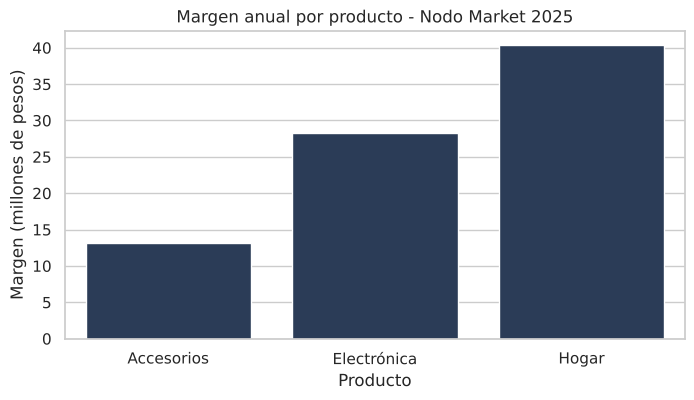

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=por_producto.index, y=por_producto["margen"] / 1e6, color=AZUL, ax=ax)   # una barra por producto
ax.set_title("Margen anual por producto - Nodo Market 2025")
ax.set_xlabel("Producto")
ax.set_ylabel("Margen (millones de pesos)")
plt.show()

**Interpretación:** hogar y electrónica generan casi todo el margen. Los accesorios, que son lo que más se vende en unidades, son lo que menos margen aporta. Cualquier decisión que mire solo los accesorios va a subestimar (o sobreestimar) el negocio.

**Gráfico 2. Evolución temporal:** ¿cuántas unidades de accesorios se piden por día? Sumamos los dos canales y dibujamos la serie con su **promedio móvil de 7 días** (que suaviza el ruido).

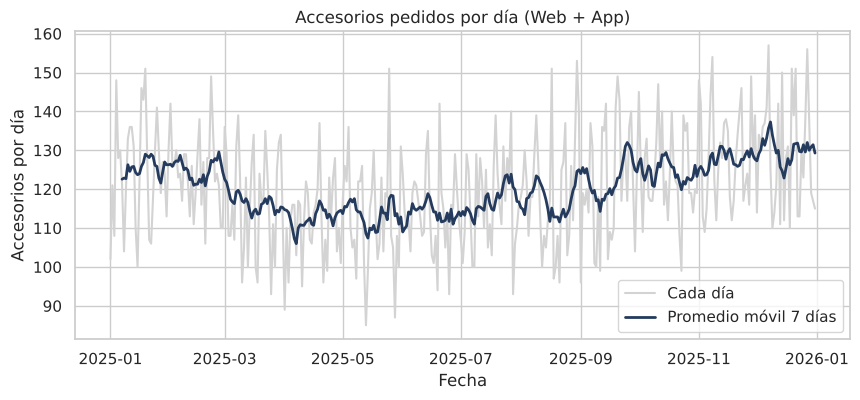

Demanda diaria: promedio 120.4, desvío 14.0


In [22]:
accesorios = ventas[ventas["producto"] == "Accesorios"]                 # nos quedamos solo con los accesorios
demanda_dia = accesorios.groupby("fecha")["cantidad"].sum()            # total por día (Web + App)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(demanda_dia.index, demanda_dia.values, color="lightgray", label="Cada día")
ax.plot(demanda_dia.index, demanda_dia.rolling(7).mean(), color=AZUL, lw=2, label="Promedio móvil 7 días")   # rolling(7): promedia cada día con los 6 anteriores
ax.set_title("Accesorios pedidos por día (Web + App)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Accesorios por día")
ax.legend()
plt.show()

mu_demanda, sigma_demanda = demanda_dia.mean(), demanda_dia.std()      # promedio y desvío de la demanda diaria
print(f"Demanda diaria: promedio {mu_demanda:.1f}, desvío {sigma_demanda:.1f}")

**Interpretación:** la demanda es **más alta en los meses de campaña** (el promedio móvil se levanta en noviembre, diciembre y enero, con la publicidad de Black Friday y Cyber Monday) y **más baja a mitad de año**. Además, de un día a otro salta mucho. Dos números de esta serie van a volver más adelante: el **promedio (~120)** y el **desvío (~14)**. Los dos salieron de los datos, no de un supuesto.

**Gráfico 3. Relación entre dos variables:** ¿qué explica los pedidos de cada día? Probamos con una **regresión lineal** (clase 15.5): predecir los accesorios del día a partir de la inversión en publicidad y de si es fin de semana.

Por cada $ 1.000 más de publicidad: +1.31 unidades
Si es fin de semana              : +16.91 unidades
R² (qué parte de la variación explica el modelo): 0.55


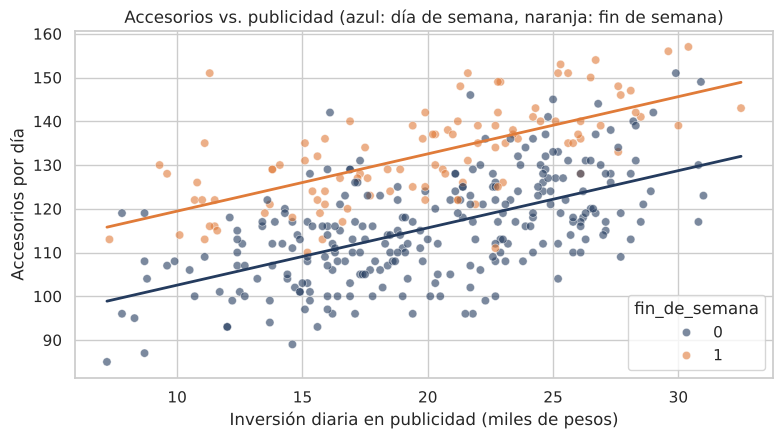

In [23]:
# Una fila por día: los accesorios totales, la publicidad y si es fin de semana
dias = accesorios.groupby("fecha").agg(accesorios=("cantidad", "sum"), publicidad=("publicidad", "first"),
                                       fin_de_semana=("fin_de_semana", "first")).reset_index()

X = dias[["publicidad", "fin_de_semana"]]      # variables que explican (2 columnas)
y = dias["accesorios"]                          # variable a explicar
modelo = LinearRegression().fit(X, y)           # ajustamos la recta (en realidad un plano) por mínimos cuadrados

print(f"Por cada $ 1.000 más de publicidad: {modelo.coef_[0]:+.2f} unidades")
print(f"Si es fin de semana              : {modelo.coef_[1]:+.2f} unidades")
print(f"R² (qué parte de la variación explica el modelo): {modelo.score(X, y):.2f}")

# Gráfico: puntos de cada día, y la recta del modelo para días de semana y para fines de semana
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=dias, x="publicidad", y="accesorios", hue="fin_de_semana", palette=[AZUL, NARANJA], alpha=0.6, ax=ax)
t = np.linspace(dias["publicidad"].min(), dias["publicidad"].max(), 50)
for fin, color in [(0, AZUL), (1, NARANJA)]:
    ax.plot(t, modelo.predict(pd.DataFrame({"publicidad": t, "fin_de_semana": fin})), color=color, lw=2)
ax.set_title("Accesorios vs. publicidad (azul: día de semana, naranja: fin de semana)")
ax.set_xlabel("Inversión diaria en publicidad (miles de pesos)")
ax.set_ylabel("Accesorios por día")
plt.show()

**Interpretación:** hay una relación **positiva** clara: por cada \$ 1.000 más de publicidad diaria entran ~1,3 unidades más, y los fines de semana ~17 más. El modelo explica **cerca de 55%** de la variación. El 45% restante es azar que no podemos predecir, y esa es la parte que se **simula** con Monte Carlo (Parte F).

Ojo: la regresión muestra *asociación*, no causalidad. Acá la relación la pusimos nosotros, pero con datos reales podría ser al revés: que se invierta más publicidad justo los días en que ya se espera vender más.

> **Para el TP:** estos pasos (cargar → mirar → limpiar → agrupar → graficar → interpretar) son exactamente los puntos 3.1 a 3.4 del enunciado.

---
# D. ¿Llega la plata a fin de mes? (clase 15)

Un depósito automatizado puede tener **VAN positivo** y aun así **dejar a la tienda sin plata** el mes que se paga. Rentable no es lo mismo que **líquido**. Armamos el flujo de caja mensual de 2025 con las ventas de la Parte C y las reglas de cobro y pago de Nodo Market:

- **Cobros:** el 60% de las ventas se cobra **en el mes** (transferencia y débito) y el 40% **al mes siguiente** (tarjetas de crédito en cuotas: la plataforma de pagos acredita con demora).
- **Mora:** es el % de lo vendido a crédito que **no llega a tiempo** (contracargos, acreditaciones demoradas).
- **Pagos a proveedores:** la mitad del costo de la mercadería se paga en el mes y la mitad al siguiente.
- **Costos fijos:** sueldos, alquiler y servicios; más **impuestos del 8%** de las ventas.
- **Caja inicial:** \$ 11 millones (más o menos un mes de gastos).

In [24]:
# Ventas y costo de mercadería de cada mes (salen de la Parte C)
mensual = ventas.groupby("mes").agg(ventas=("ingreso", "sum"), cmv=("cmv", "sum"))
mensual.index = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# Supuestos de la tienda (cambiá estos números y volvé a correr)
SUELDOS, ALQUILER, SERVICIOS = 2_900_000, 1_000_000, 700_000
IMPUESTOS_PCT = 0.08                       # impuestos: 8% de las ventas
CAJA_INICIAL = 11_000_000
MES_COMPRA = 2                             # el depósito se compra en marzo (posición 2: Ene=0, Feb=1, Mar=2)
FLUJO_DEPOSITO_ANUAL = 3_200_000              # lo que deja el depósito en su año 1 (de la Parte B), repartido en 12

def caja_acumulada(proyecto="ninguno", mora=0.0, pct_credito=0.40):
    """Caja de fin de cada mes. proyecto: 'ninguno', 'contado' o 'financiado'.
    mora: % de lo vendido a crédito que NO llega a tiempo (0.20 = 20%)."""
    v, c = mensual["ventas"].to_numpy(), mensual["cmv"].to_numpy()

    contado = (1 - pct_credito) * v                                      # lo que se cobra en el mes
    credito = pct_credito * v
    cobrado_credito = np.r_[credito[0], credito[:-1]] * (1 - mora)       # lo del mes anterior (enero: suponemos igual a enero)
    pagos_prov = 0.5 * c + 0.5 * np.r_[c[0], c[:-1]]                     # mitad en el mes, mitad al siguiente
    fijos = SUELDOS + ALQUILER + SERVICIOS + IMPUESTOS_PCT * v

    saldo = contado + cobrado_credito - pagos_prov - fijos               # lo que queda cada mes

    extra = np.zeros(12)                                                 # movimientos del proyecto, mes a mes
    if proyecto != "ninguno":
        extra[MES_COMPRA + 1:] += FLUJO_DEPOSITO_ANUAL / 12                 # el depósito empieza a dejar plata
        if proyecto == "contado":
            extra[MES_COMPRA] -= 9_000_000                              # se paga todo en marzo
        else:
            extra[MES_COMPRA] += PRESTAMO - 9_000_000                   # entra el préstamo y se paga el depósito
            extra[MES_COMPRA + 1:] -= cuota                              # y se paga la cuota (la de la Parte A)
    return pd.Series(CAJA_INICIAL + np.cumsum(saldo + extra), index=mensual.index)

# Egreso mensual promedio (sirve para medir "cuántos meses de gastos tenemos en caja")
egreso_prom = mensual["cmv"].mean() + SUELDOS + ALQUILER + SERVICIOS + IMPUESTOS_PCT * mensual["ventas"].mean()
print("Egreso mensual promedio:", pesos(egreso_prom))

Egreso mensual promedio: $ 11.309.530


### D1. Los KPI de proceso: DSO, DPO y CCC

Con las reglas de arriba podemos calcular los tres indicadores de la clase 15:

- **DSO**: días promedio que tardamos en cobrar. **DPO**: días promedio que tardamos en pagar.
- **CCC** (ciclo de conversión de caja) $= DSO - DPO$: cuántos días financiamos la operación con plata propia.

In [25]:
dso = 0.40 * 30        # el 40% de las ventas se cobra a 30 días, el 60% al instante -> en promedio 12 días
dpo = 0.50 * 30        # la mitad de las compras se paga a 30 días, la otra mitad al instante -> 15 días
ccc = dso - dpo

print(f"DSO: {dso:.0f} días | DPO: {dpo:.0f} días | CCC: {ccc:.0f} días")

DSO: 12 días | DPO: 15 días | CCC: -3 días


El CCC da **negativo (-3 días)**: Nodo Market les paga a los proveedores **después** de cobrarles a los clientes, o sea que los proveedores le financian el capital de trabajo. Es habitual en el ecommerce (se cobra al comprar y se paga después). Pero esa comodidad se rompe si las acreditaciones empiezan a **atrasarse (mora)**.

### D2. ¿Qué pasa con la caja? Tres opciones y mora del 10%

Comparamos la caja de Nodo Market si **no compra** el depósito, si lo paga **al contado** en marzo y si lo **financia** (\$ 3,5 M propios + \$ 5,5 M del banco):

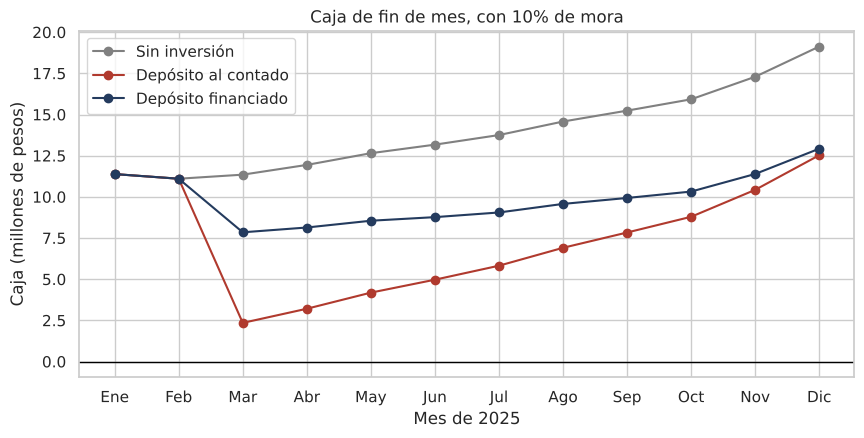

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for proyecto, color, nombre in [("ninguno", "gray", "Sin inversión"), ("contado", ROJO, "Depósito al contado"), ("financiado", AZUL, "Depósito financiado")]:
    ax.plot(caja_acumulada(proyecto, mora=0.10) / 1e6, marker="o", color=color, label=nombre)     # caja_acumulada devuelve una Serie por mes

ax.axhline(0, color="black", lw=1)                          # debajo de cero: no se puede pagar
ax.set_title("Caja de fin de mes, con 10% de mora")
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Caja (millones de pesos)")
ax.legend()
plt.show()

**Cómo se lee:** pagar al contado hace que la caja **se desplome en marzo** hasta \$ 2,35 M (un mes de gastos son \$ 11 M): no queda colchón para ningún imprevisto, aunque el depósito "convenga". Financiado, la caja baja mucho menos (su punto más bajo es \$ 7,85 M), aunque queda por debajo de la línea sin depósito: se está pagando una cuota todos los meses.

### D3. ¿Cuánta mora aguanta? El semáforo

Cruzamos la **mora** (0%, 10%, 20%, 30%) con las dos formas de pagar el depósito, y le ponemos un **semáforo** según cuántos meses de gastos hay en la peor caja del año (la clase 15 lo llamaba *runway*): 🟢 un mes o más de gastos, 🟡 entre medio mes y un mes, 🟠 menos de medio mes, 🔴 caja negativa.

No incluimos acá la opción "sin depósito": ya la vimos en el gráfico anterior como referencia, y lo que nos interesa ahora es **comparar las dos formas de pagar**.

In [27]:
def semaforo(caja_minima):
    meses = caja_minima / egreso_prom            # cuántos meses de gastos cubre la caja mínima
    if caja_minima < 0:  return "🔴"             # caja negativa: no se puede pagar
    if meses < 0.5:      return "🟠"             # menos de medio mes de gastos
    if meses < 1:        return "🟡"             # menos de un mes
    return "🟢"                                  # un mes o más

filas = []
for mora in [0, 0.10, 0.20, 0.30]:
    fila = {"Mora": f"{mora:.0%}"}
    for proyecto in ["contado", "financiado"]:
        minima = caja_acumulada(proyecto, mora).min()                  # la caja más baja del año
        fila[proyecto] = f"{semaforo(minima)} {minima / 1e6:+.2f} M"
    filas.append(fila)

pd.DataFrame(filas).set_index("Mora")

,contado,financiado
Mora,,
0%,🟠 +3.66 M,🟡 +9.16 M
10%,🟠 +2.35 M,🟡 +7.85 M
20%,🟠 +1.03 M,🟠 +5.55 M
30%,🔴 -0.76 M,🟠 +0.77 M


¿Y hasta cuánta mora aguanta cada opción? Probamos moras de 0% a 40% de a un punto y nos quedamos con la primera en la que la caja se vuelve **negativa** en algún mes:

In [28]:
for proyecto in ["contado", "financiado"]:
    for mora in np.arange(0, 0.41, 0.01):                        # 0%, 1%, 2%, ... 40%
        if caja_acumulada(proyecto, mora).min() < 0:             # ¿la caja más baja del año es negativa?
            print(f"{proyecto.capitalize():11s}: la caja se vuelve negativa a partir de una mora de {mora:.0%}")
            break                                                # frenamos en la primera que cumple

Contado    : la caja se vuelve negativa a partir de una mora de 28%
Financiado : la caja se vuelve negativa a partir de una mora de 32%


**Interpretación:** con **mora 0%**, financiar es 🟡 y pagar al contado ya es 🟠 (casi sin colchón). Con **20% de mora**, los dos quedan en 🟠, pero con colchones muy distintos (+1,03 M al contado, +5,55 M financiado). El financiamiento **compra margen de seguridad**. Con una **mora del 30%**, al contado la caja ya es negativa (🔴, -0,76 M); financiado todavía alcanza (🟠, +0,77 M), aunque sin colchón. Moraleja de la clase 15: el depósito hay que evaluarlo *junto con* el riesgo de cobranza.

### D4. Una palanca de proceso: cobrar más al contado

Si Nodo Market empuja a que **menos clientes paguen con tarjeta en cuotas** (del 40% al 25%, con un descuento por pagar con transferencia), ¿cuánta caja libera? Es el paso "del KPI de proceso al impacto en caja" de la clase 15:

In [29]:
for pct in [0.40, 0.25]:
    minima = caja_acumulada("financiado", mora=0.20, pct_credito=pct).min()
    print(f"Con {pct:.0%} de ventas a crédito (financiado, mora 20%): caja mínima {millones(minima)} {semaforo(minima)}")

Con 40% de ventas a crédito (financiado, mora 20%): caja mínima $ 5,55 M 🟠
Con 25% de ventas a crédito (financiado, mora 20%): caja mínima $ 7,60 M 🟡


Mover **15 puntos** de las ventas de crédito a contado pasa la caja de 🟠 a 🟡 (de \$ 5,55 M a \$ 7,60 M de caja mínima): **un cambio de proceso vale tanto como negociar un mejor precio por el depósito**.

---
# E. ¿Cuánto producir y cuánto vale lo acumulado? (clase 16)

Las integrales sirven para pasar de lo **marginal** (lo que cuesta o rinde *una unidad más*) a lo **total** o **acumulado**. Con el depósito automatizado aparece una pregunta concreta: **¿cuánto baja el costo de despachar un pedido, y cuánto aporta eso a los \$ 3,2 millones por año que esperamos?**

Para esto nos concentramos en los **accesorios**, que se venden con el servicio **"Llega hoy"**: cada pedido se prepara y se despacha el mismo día. Le decimos **pedido express** a cada unidad despachada así.

Supuestos de la clase (son **supuestos**, no datos), calibrados para que den lo mismo que los datos de la Parte C a 120 pedidos express por día:

- **Demanda** (precio al que se vende el pedido número $q$): $p(q) = 800 - 2{,}5\,q$. A 120 pedidos por día, el precio es \$ 500.
- **Costo marginal con el depósito actual (operador logístico):** $CMg_{viejo}(q) = 80 + q$ (los últimos pedidos del día cuestan más: horas extra, courier urgente). A 120, cuesta \$ 200.
- **Costo marginal con el depósito automatizado:** $CMg_{nuevo}(q) = 80 + 0{,}6\,q$ (más eficiente a escala: la automatización absorbe los picos).

Conviene despachar hasta que **el último pedido deje de dar ganancia**: cuando el ingreso marginal iguala al costo marginal. El **beneficio** es la **integral definida** de $IMg - CMg$ entre 0 y esa cantidad (el acumulado de "lo que deja cada pedido").

In [30]:
q = sp.symbols("q", nonnegative=True)                 # q: pedidos express por día

p_demanda = 800 - sp.Rational(5, 2) * q               # precio al que se vende el pedido q
IMg = sp.diff(p_demanda * q, q)                       # ingreso marginal: la derivada del ingreso total (clase 10)
CMg_viejo = 80 + q                                    # costo marginal con el depósito actual
CMg_nuevo = 80 + sp.Rational(3, 5) * q                # costo marginal con el depósito automatizado

resultados = {}
for nombre, CMg in [("Depósito actual", CMg_viejo), ("Depósito automatizado", CMg_nuevo)]:
    q_opt = sp.solve(sp.Eq(IMg, CMg), q)[0]                       # IMg(q) = CMg(q)
    p_opt = p_demanda.subs(q, q_opt)                              # precio al que se vende esa cantidad
    beneficio = sp.integrate(IMg - CMg, (q, 0, q_opt))            # integral definida: acumulado de (IMg - CMg)
    resultados[nombre] = (q_opt, p_opt, beneficio)
    print(f"{nombre}: despachar {float(q_opt):.1f} pedidos express por día, a un precio de {pesos(float(p_opt))}, "
          f"beneficio de {pesos(float(beneficio))} por día")

q_viejo, p_viejo, b_viejo = resultados["Depósito actual"]
q_nuevo, p_nuevo, b_nuevo = resultados["Depósito automatizado"]

mejora_total = b_nuevo - b_viejo                      # cuánto más deja por día el depósito automatizado
print(f"\nMejora del beneficio: {pesos(float(mejora_total))} por día, {pesos(float(mejora_total) * 365)} por año")
print(f"Eso es el {float(mejora_total) * 365 / 3_200_000:.0%} de los 3,2 millones que esperamos del depósito en el año 1")

Depósito actual: despachar 120.0 pedidos express por día, a un precio de $ 500, beneficio de $ 43.200 por día
Depósito automatizado: despachar 128.6 pedidos express por día, a un precio de $ 479, beneficio de $ 46.286 por día

Mejora del beneficio: $ 3.086 por día, $ 1.126.286 por año
Eso es el 35% de los 3,2 millones que esperamos del depósito en el año 1


**Interpretación:** con el depósito automatizado conviene despachar **más pedidos** (~129 en vez de 120) y venderlos **un poco más baratos** (~\$ 479 en vez de \$ 500). El beneficio sube unos \$ 3.100 por día: **~\$ 1,1 millones por año**.

Y acá viene el *chequeo de supuestos*: los accesorios explican solo **~35%** de los \$ 3,2 millones del año 1. El resto tendría que venir de hogar y electrónica (que son el 85% del ingreso, como vimos en la Parte C). Si Lucía pensaba que el depósito se pagaba con accesorios, **tenía mal el cálculo**. Es el tipo de cosa que un solo VAN no muestra.

Lo vemos en un gráfico. El área sombreada es el **ahorro** de costo: la integral entre las dos curvas de costo marginal.

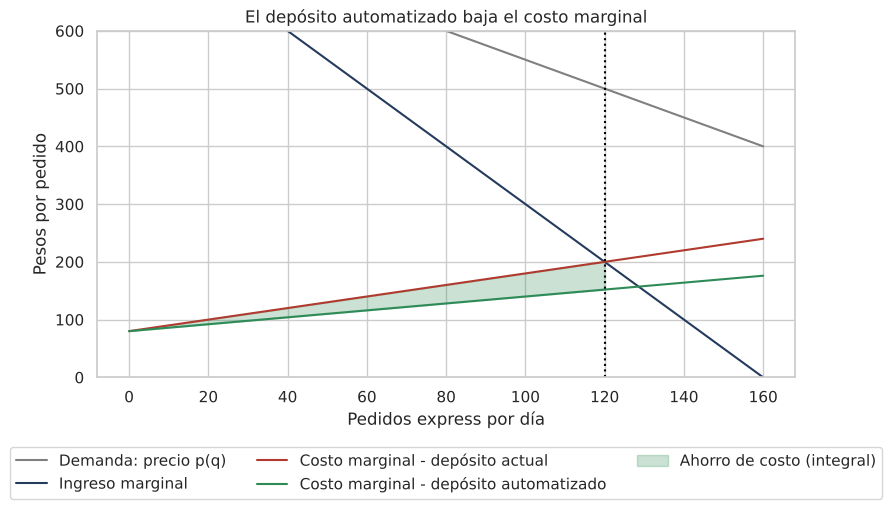

In [31]:
q_grid = np.linspace(0, 160, 300)
f = lambda expr: sp.lambdify(q, expr)(q_grid) * np.ones_like(q_grid)       # pasa una expresión de SymPy a números

qv = float(q_viejo)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(q_grid, f(p_demanda), color="gray", label="Demanda: precio p(q)")
ax.plot(q_grid, f(IMg), color=AZUL, label="Ingreso marginal")
ax.plot(q_grid, f(CMg_viejo), color=ROJO, label="Costo marginal - depósito actual")
ax.plot(q_grid, f(CMg_nuevo), color=VERDE, label="Costo marginal - depósito automatizado")
mascara = q_grid <= qv                                                      # pintamos desde 0 hasta la cantidad actual
ax.fill_between(q_grid[mascara], f(CMg_nuevo)[mascara], f(CMg_viejo)[mascara], color=VERDE, alpha=0.25, label="Ahorro de costo (integral)")
ax.axvline(qv, color="black", ls=":")
ax.set_ylim(0, 600)
ax.set_xlabel("Pedidos express por día")
ax.set_ylabel("Pesos por pedido")
ax.set_title("El depósito automatizado baja el costo marginal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)   # leyenda debajo del gráfico
plt.show()

---
# F. ¿Cuánto riesgo hay? (clase 19)

Todo lo anterior supone que los números que usamos (flujos de \$ 3,2 M, demanda de 120) son **exactos**. No lo son: son **estimaciones**. La clase 19 nos dio dos herramientas para trabajar con eso: **muestreo** (¿cuánto le creo a lo que medí?) y **Monte Carlo** (probar miles de futuros).

### F1. Muestreo: ¿cuántos días de ventas necesito para estimar la demanda?

En la Parte C teníamos **los 365 días**. Pero imaginá que Lucía solo tiene una exportación de unos pocos días. ¿Cuánto se equivoca al estimar la demanda promedio? Hacemos como en la clase 19: **100 encuestas** (muestras de días) de cada tamaño, y vemos el error promedio.

Días
5      4.1
10     3.5
20     2.3
30     1.8
60     1.2
120    0.8
240    0.4
Name: Error promedio (unidades), dtype: float64


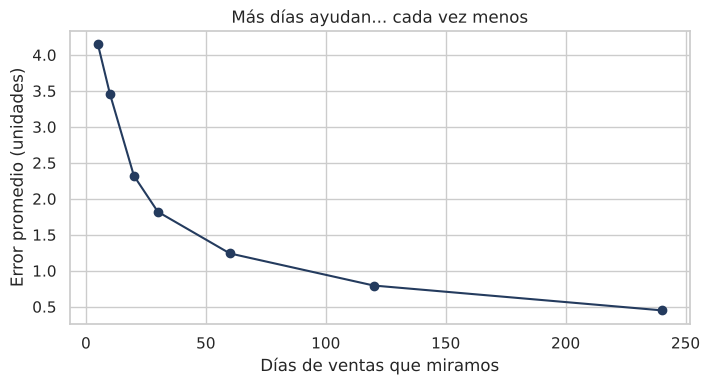

In [32]:
verdad = demanda_dia.mean()                       # la "verdad": el promedio de los 365 días (en la vida real no lo conocemos)

tamanos = [5, 10, 20, 30, 60, 120, 240]
error_promedio = []
for n in tamanos:
    errores = []
    for i in range(100):                          # 100 muestras de n días, con distinta semilla cada una
        muestra = demanda_dia.sample(n, random_state=i)
        errores.append(abs(muestra.mean() - verdad))
    error_promedio.append(np.mean(errores))

print(pd.Series(error_promedio, index=tamanos).round(1).rename("Error promedio (unidades)").rename_axis("Días"))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tamanos, error_promedio, marker="o", color=AZUL)
ax.set_xlabel("Días de ventas que miramos")
ax.set_ylabel("Error promedio (unidades)")
ax.set_title("Más días ayudan... cada vez menos")
plt.show()

**Cómo se lee:** con 5 días el promedio se equivoca por ~4 unidades; con 30 días, por ~2; con 120, por menos de 1. Duplicar los días de 120 a 240 gana apenas 0,4 unidades (el error baja de 0,8 a 0,4): la curva **cae rápido y se aplana**

Ahora, **¿importa qué días miramos?** Comparamos 30 días **al azar** con 30 días **de conveniencia**: Lucía mira solo los **fines de semana**, porque "ahí es cuando tiene tiempo de revisar los números".

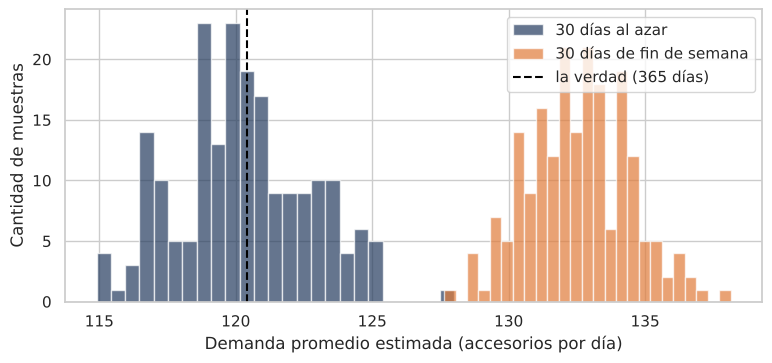

Error al azar: 0.1 | Error de conveniencia: 12.1 unidades


In [33]:
finde = demanda_dia[demanda_dia.index.dayofweek >= 5]            # solo sábados y domingos

al_azar = [demanda_dia.sample(30, random_state=i).mean() for i in range(200)]     # 200 muestras de 30 días cualquiera
conveniencia = [finde.sample(30, random_state=i).mean() for i in range(200)]      # 200 muestras de 30 fines de semana

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(al_azar, bins=25, alpha=0.7, color=AZUL, label="30 días al azar")
ax.hist(conveniencia, bins=25, alpha=0.7, color=NARANJA, label="30 días de fin de semana")
ax.axvline(verdad, color="black", ls="--", label="la verdad (365 días)")
ax.set_xlabel("Demanda promedio estimada (accesorios por día)")
ax.set_ylabel("Cantidad de muestras")
ax.legend(loc="upper right")
plt.show()
print(f"Error al azar: {abs(np.mean(al_azar) - verdad):.1f} | Error de conveniencia: {abs(np.mean(conveniencia) - verdad):.1f} unidades")

**El sesgo no se arregla con más datos:** si Lucía mira solo los fines de semana, **sobreestima la demanda de manera sistemática**, por unas 12 unidades por día (todas las muestras naranjas caen a la derecha de la verdad). Y como se puede decidir mal el depósito por mirar los días equivocados, vale lo de la clase 19: *antes de preguntar cuántos datos hay, preguntá quiénes son.*

### F2. Monte Carlo: ¿qué tan seguro es el VAN?

Es el caso 2 de la clase 19, ahora con el depósito. El VAN de +0,36 M supone que los flujos son exactos. Simulamos **10.000 futuros**: en cada uno, cada flujo sale mejor o peor que lo esperado (con un desvío del **20%**), y calculamos el VAN de ese futuro con la función `van` de la Parte B.

VAN esperado (Parte B)        : +0.36 M
VAN promedio de los 10.000    : +0.35 M
Futuros donde se pierde plata : 34.5%
El 5% de los peores futuros pierde más de 1.11 M


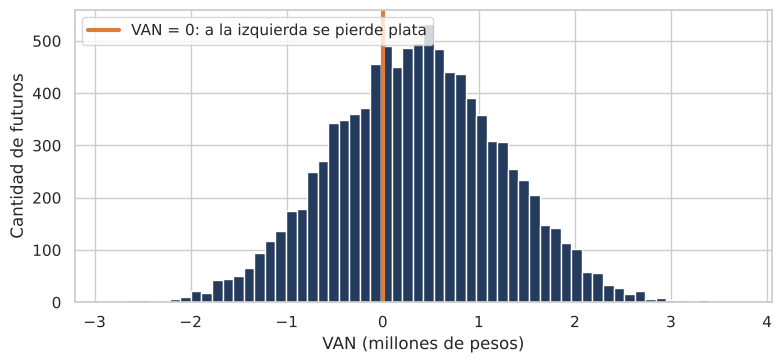

In [34]:
rng = np.random.default_rng(7)
esperados = flujos[1:]                                    # los 5 flujos esperados (años 1 a 5)
vans = []                                                 # acá guardamos el VAN de cada futuro

for i in range(10_000):                                   # cada vuelta es un futuro posible
    simulados = rng.normal(esperados, 0.20 * esperados)   # cada flujo sale de una campana centrada en lo esperado
    futuro = np.r_[flujos[0], simulados]                  # le pegamos adelante la inversión (año 0)
    vans.append(van(futuro, R) / 1e6)                     # VAN de este futuro, en millones

vans = pd.Series(vans)

print(f"VAN esperado (Parte B)        : {van(flujos, R) / 1e6:+.2f} M")
print(f"VAN promedio de los 10.000    : {vans.mean():+.2f} M")
print(f"Futuros donde se pierde plata : {(vans < 0).mean():.1%}")
print(f"El 5% de los peores futuros pierde más de {-np.percentile(vans, 5):.2f} M")

plt.figure(figsize=(9, 3.8))
plt.hist(vans, bins=60, color=AZUL)
plt.axvline(0, color=NARANJA, lw=3, label="VAN = 0: a la izquierda se pierde plata")
plt.xlabel("VAN (millones de pesos)")
plt.ylabel("Cantidad de futuros")
plt.legend(loc="upper left")
plt.show()

**Interpretación:** en **promedio** el depósito conviene (VAN +0,35 M), pero en **~35% de los futuros hace perder plata**: una chance en tres. El número solo ("+0,36") escondía ese riesgo.

¿De dónde sale el desvío de 20%? **De un supuesto**, no de datos (con varios años de ventas reales se podría estimar). Una simulación vale lo que valen sus supuestos.

### ⭐ Extra (opcional): para hacer doble click

No hace falta para seguir la clase ni para el TP. Son dos vueltas de tuerca para quien quiera ir más allá.

**1. Lo mismo, sin `for`.** `rng.normal` puede devolver una tabla entera de una vez: 10.000 filas (una por futuro) y 5 columnas (una por año). Es más rápido y da exactamente los mismos números. Con eso es fácil ver cuánto cambia el riesgo si la incertidumbre es mayor o menor:

In [35]:
def simular_van(desvio, n_futuros=10_000, semilla=7):
    rng = np.random.default_rng(semilla)
    # tabla de n_futuros filas x 5 columnas: cada flujo sale de una campana centrada en lo esperado
    sim = rng.normal(esperados, desvio * esperados, size=(n_futuros, 5))
    años_flujos = np.arange(1, 6)                                         # años 1 a 5
    return ((sim / (1 + R) ** años_flujos).sum(axis=1) - inversion) / 1e6  # VAN de cada futuro (sum por filas), en millones

print("¿Da lo mismo que con el for?", np.allclose(simular_van(0.20), vans))

filas = []
for desvio in [0.10, 0.20, 0.30, 0.40]:
    v = simular_van(desvio)
    filas.append({"Desvío de los flujos": f"{desvio:.0%}", "VAN promedio (M)": v.mean(),
                  "Prob. de perder plata": f"{(v < 0).mean():.1%}", "Peor 5% (M)": np.percentile(v, 5)})
pd.DataFrame(filas).set_index("Desvío de los flujos").round(2)

¿Da lo mismo que con el for? True


,VAN promedio (M),Prob. de perder plata,Peor 5% (M)
Desvío de los flujos,,,
10%,0.36,21.4%,-0.37
20%,0.35,34.5%,-1.11
30%,0.35,39.8%,-1.84
40%,0.34,42.3%,-2.58


El VAN promedio casi no cambia (de 0,36 a 0,34 M), pero la **probabilidad de perder** sube rápido con la incertidumbre: de 21% con un desvío de 10% a 42% con uno de 40%.

**2. Otro Monte Carlo: ¿cuántos pedidos express preparar por día?** Es el caso de las medialunas de la clase 19, con los datos de Nodo Market.

Cada día hay que decidir **con anticipación** cuántos pedidos express se preparan (se reservan los cupos con el courier y se arma el picking). Cada pedido preparado cuesta **\$ 200** (se venda o no); cada pedido que se cobra deja **\$ 500**. Si piden más de lo preparado, ese pedido se pierde; si piden menos, se pierde el costo de lo sobrante (simplificación: no recuperamos nada).

Usamos como **demanda** una campana con el promedio y el desvío que **medimos en la Parte C** (no los 120 y 15 "de la clase 19": ahora son estimaciones de nuestros datos). Probamos todas las cantidades de 90 a 160 y nos quedamos con la que deja más ganancia **promedio** en 1.000 días simulados.

Y comparamos el **depósito actual** (cuesta \$ 200 cada pedido) con el **automatizado** (el costo marginal a 120 pedidos que sale de la Parte E).

Depósito actual (costo $ 200): preparar 124 -> ganancia $ 33.267 por día
Depósito automatizado (costo $ 152): preparar 127 -> ganancia $ 39.272 por día
Con los días reales como escenarios (depósito actual): preparar 123


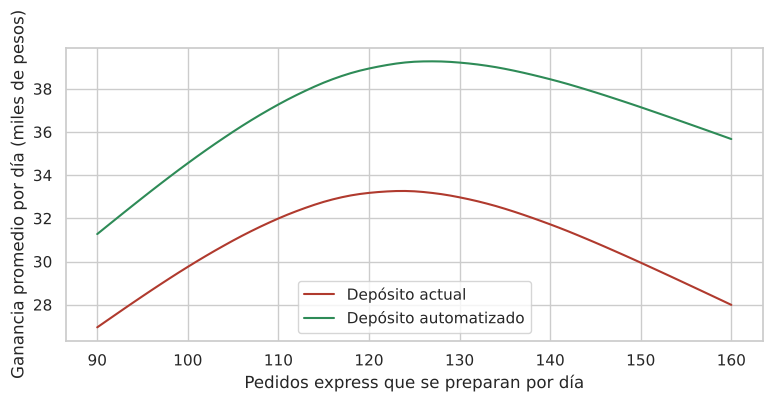

In [36]:
PRECIO = 500                                              # lo que se cobra por pedido express
COSTO_VIEJO = float(CMg_viejo.subs(q, 120))               # costo de un pedido con el depósito actual, a 120 por día (la Parte E): 200
COSTO_NUEVO = float(CMg_nuevo.subs(q, 120))               # y con el depósito automatizado: 152

rng = np.random.default_rng(8)
# 1.000 días simulados: campana con el promedio y desvío medidos en la Parte C; sin números negativos
demanda_sim = rng.normal(mu_demanda, sigma_demanda, size=1000).round().clip(min=0)

def ganancia_promedio(preparar, costo, demanda):
    vendidas = np.minimum(demanda, preparar)                    # se vende lo que piden, con el tope de lo preparado
    return (vendidas * PRECIO - preparar * costo).mean()         # se cobran las vendidas, se pagan TODAS las preparadas

cantidades = np.arange(90, 161)                                  # 90, 91, ..., 160
curva_viejo = np.array([ganancia_promedio(h, COSTO_VIEJO, demanda_sim) for h in cantidades])
curva_nuevo = np.array([ganancia_promedio(h, COSTO_NUEVO, demanda_sim) for h in cantidades])

mejor_viejo, mejor_nuevo = cantidades[curva_viejo.argmax()], cantidades[curva_nuevo.argmax()]   # argmax: la posición del máximo
print(f"Depósito actual (costo {pesos(COSTO_VIEJO)}): preparar {mejor_viejo} -> ganancia {pesos(curva_viejo.max())} por día")
print(f"Depósito automatizado (costo {pesos(COSTO_NUEVO)}): preparar {mejor_nuevo} -> ganancia {pesos(curva_nuevo.max())} por día")

# El mismo cálculo, pero usando los 365 días REALES como "futuros posibles" (sin suponer ninguna campana)
curva_real = np.array([ganancia_promedio(h, COSTO_VIEJO, demanda_dia.to_numpy()) for h in cantidades])
print(f"Con los días reales como escenarios (depósito actual): preparar {cantidades[curva_real.argmax()]}")

plt.figure(figsize=(9, 3.8))
plt.plot(cantidades, curva_viejo / 1e3, color=ROJO, label="Depósito actual")
plt.plot(cantidades, curva_nuevo / 1e3, color=VERDE, label="Depósito automatizado")
plt.xlabel("Pedidos express que se preparan por día")
plt.ylabel("Ganancia promedio por día (miles de pesos)")
plt.legend()
plt.show()

**Interpretación:** con el depósito automatizado la ganancia por día es **más alta** y conviene preparar **más** pedidos. Fijate que esto es **un modelo distinto** al de la Parte E (acá la demanda es incierta y el costo es fijo por unidad; allá la demanda es una curva y el costo marginal sube), pero **llega a una conclusión parecida**: con el depósito automatizado se preparan **entre 127 y 129 pedidos** por día (contra 120 a 124 con el actual). Cuando dos métodos independientes coinciden, la conclusión es más confiable.

---
# G. Antes de presentar: ¿nos estamos mintiendo con los datos?

Lucía tiene que defender el depósito ante el banco y ante sus socios. Todos los números de arriba se pueden mostrar de forma **honesta** o **engañosa** sin falsificar un solo dato. Repasamos las trampas de la clase [**Cómo mentir con datos y cómo darte cuenta**](https://manuelfsm03.github.io/labo-fce/mentir-con-datos/) (Manuel Fernández San Martín, Laboratorio de Métodos Cuantitativos, FCE-UBA) **aplicadas a nuestros propios números**, en el mismo orden que allá: lo que se **elige**, lo que se **calcula** y lo que se **ve**.

## Lo que se elige

**¿A quién le preguntaste?** Ya lo vimos en F1: si Lucía mira solo los fines de semana, sobreestima la demanda en unas 12 unidades por día. El problema no es cuántos datos mira, sino cuáles.

### G1. Elegí la ventana, elegí la historia

Con la serie de accesorios por día de la Parte C: ¿la demanda **sube** o **baja**? Depende de qué 30 días mires. Calculamos la pendiente de **todas** las ventanas posibles de 30 días:

Ventanas de 30 días: 336. En 184 la demanda sube y en 152 baja.


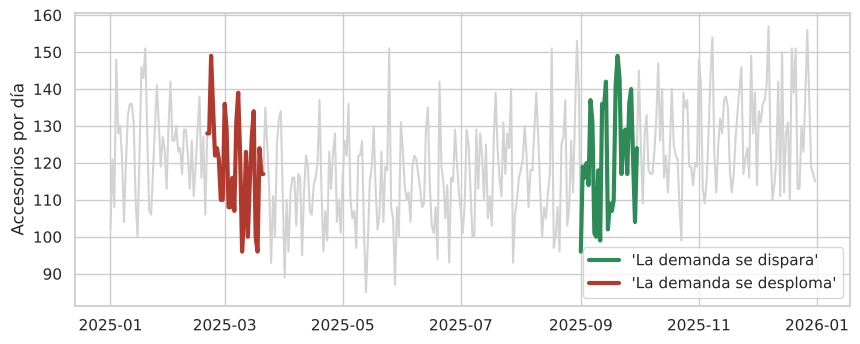

In [37]:
valores = demanda_dia.to_numpy()
ventana = 30
x = np.arange(ventana)

# Pendiente de la recta de cada ventana de 30 días consecutivos (polyfit grado 1 = recta)
pendientes = np.array([np.polyfit(x, valores[i:i + ventana], 1)[0] for i in range(len(valores) - ventana + 1)])
print(f"Ventanas de 30 días: {len(pendientes)}. En {(pendientes > 0).sum()} la demanda sube y en {(pendientes < 0).sum()} baja.")

i_sube, i_baja = pendientes.argmax(), pendientes.argmin()     # la ventana que más "sube" y la que más "baja"
plt.figure(figsize=(10, 3.8))
plt.plot(demanda_dia.index, valores, color="lightgray")
plt.plot(demanda_dia.index[i_sube:i_sube + ventana], valores[i_sube:i_sube + ventana], color=VERDE, lw=3, label="'La demanda se dispara'")
plt.plot(demanda_dia.index[i_baja:i_baja + ventana], valores[i_baja:i_baja + ventana], color=ROJO, lw=3, label="'La demanda se desploma'")
plt.ylabel("Accesorios por día")
plt.legend()
plt.show()

**Cómo se lee:** hay 336 ventanas posibles; en 184 la demanda sube y en 152 baja. Con tantas, **siempre** se puede encontrar una que "demuestre" lo que uno quiera. Es el *cherry picking*. La defensa es mostrar **la serie completa**, o decir por qué se eligió esa ventana (y no otra).

## Lo que se calcula

### G2. Porcentajes que asustan, con los números del depósito

Tres pares de frases que Lucía podría decir sobre **el mismo proyecto**. En cada par, las dos son ciertas:

In [38]:
roi = flujos[1:].sum() / inversion - 1                    # Parte B: lo que gana sobre lo que puso, sin mirar el tiempo
print(f'1) "El depósito rinde {roi:.0%}" (ROI)  ...o...  "rinde {tir(flujos):.1%} por año" (TIR)')

mora_antes, mora_despues = 0.10, 0.20                     # Parte D: dos escenarios de mora
print(f'2) "La mora subió {(mora_despues - mora_antes) * 100:.0f} puntos"  ...o...  "la mora se duplicó ({mora_despues / mora_antes - 1:+.0%})"')

print(f'3) "La plata cuesta {wacc_nominal:.1%} por año" (nominal)  ...o...  "cuesta {wacc_real:.1%}" (real, Parte A)')

1) "El depósito rinde 69%" (ROI)  ...o...  "rinde 21.6% por año" (TIR)
2) "La mora subió 10 puntos"  ...o...  "la mora se duplicó (+100%)"
3) "La plata cuesta 46.7% por año" (nominal)  ...o...  "cuesta 19.7%" (real, Parte A)


**Cómo se lee:** cada frase sirve para contar una historia distinta.
1. El **ROI** suma la plata de cinco años sin mirar **cuándo** llega, y por eso suena espectacular. La **TIR** es lo que rinde **por año** (Parte B).
2. **Puntos porcentuales vs. porcentaje relativo:** según cuál elijas, la noticia suena a "casi nada" o a "se duplicó".
3. **Nominal vs. real:** si alguien descuenta los flujos del depósito (que están en pesos de hoy) al 46,7%, el proyecto parece un desastre sin serlo (Parte A4).

La defensa son tres preguntas: **¿por año o en total? ¿puntos o porcentaje? ¿nominal o real?**

### G3. Correlación no es causalidad (con una verdad que conocemos)

En la Parte C la publicidad explicaba los accesorios. ¿Y las ventas de **hogar**? Como los datos los fabricamos nosotros, sabemos la verdad: **la publicidad no mueve hogar** (fijate la celda que arma la base: hogar depende del día y del mes, no de la publicidad). Igual medimos la correlación:

Correlación publicidad-hogar en todo el año        : +0.23
Correlación publicidad-hogar dentro de cada mes    : -0.03  (promedio de los 12 meses)


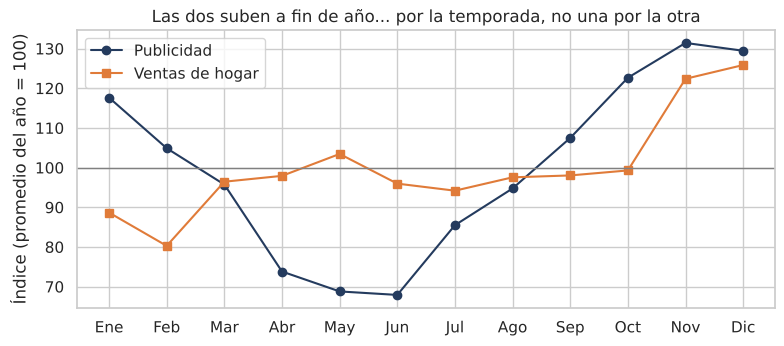

In [39]:
# Una fila por día: unidades de cada producto y la publicidad de ese día
por_dia = ventas.groupby(["fecha", "producto"])["cantidad"].sum().unstack()
por_dia["publicidad"] = ventas.groupby("fecha")["publicidad"].first()
por_dia["mes"] = por_dia.index.month

print(f"Correlación publicidad-hogar en todo el año        : {por_dia['publicidad'].corr(por_dia['Hogar']):+.2f}")
dentro = por_dia.groupby("mes").apply(lambda m: m["publicidad"].corr(m["Hogar"]))      # la misma cuenta, mes por mes
print(f"Correlación publicidad-hogar dentro de cada mes    : {dentro.mean():+.2f}  (promedio de los 12 meses)")

# Las dos series por mes, como índice (promedio del año = 100) para verlas en la misma escala
indice = por_dia.groupby("mes")[["publicidad", "Hogar"]].mean()
indice = indice / indice.mean() * 100
indice.index = mensual.index                                                            # Ene, Feb, ..., Dic

plt.figure(figsize=(9, 3.6))
plt.plot(indice.index, indice["publicidad"], marker="o", color=AZUL, label="Publicidad")
plt.plot(indice.index, indice["Hogar"], marker="s", color=NARANJA, label="Ventas de hogar")
plt.axhline(100, color="gray", lw=1)
plt.ylabel("Índice (promedio del año = 100)")
plt.title("Las dos suben a fin de año... por la temporada, no una por la otra")
plt.legend()
plt.show()

**Cómo se lee:** en todo el año, publicidad y hogar van juntas, y parece que la publicidad vende hogar. Pero **dentro de cada mes la relación desaparece**. Lo que mueve a las dos es una **tercera causa**: la temporada (Black Friday, Cyber Monday y fiestas), cuando se invierte más en publicidad y también se compra más para la casa. Fijate que para comparar dos series en unidades distintas usamos un **índice** (promedio = 100), no un gráfico con dos ejes: con dos ejes, quien arma el gráfico elige cuál "gana".

Antes de decir "A causa B", las cuatro preguntas de siempre: ¿hay una **tercera causa**? ¿será **al revés**? ¿será **casualidad**? ¿es una **tendencia común**? (La relación publicidad-accesorios de la Parte C es real porque la pusimos nosotros, pero con datos reales podría ser al revés: que se invierta más publicidad justo los días en que ya se espera vender más.)

## Lo que se ve

### G4. El eje que no arranca en cero

El gráfico de la Parte B compara lo que rinde el depósito con lo que cuesta la plata. Si Lucía se lo lleva al banco con el eje recortado...

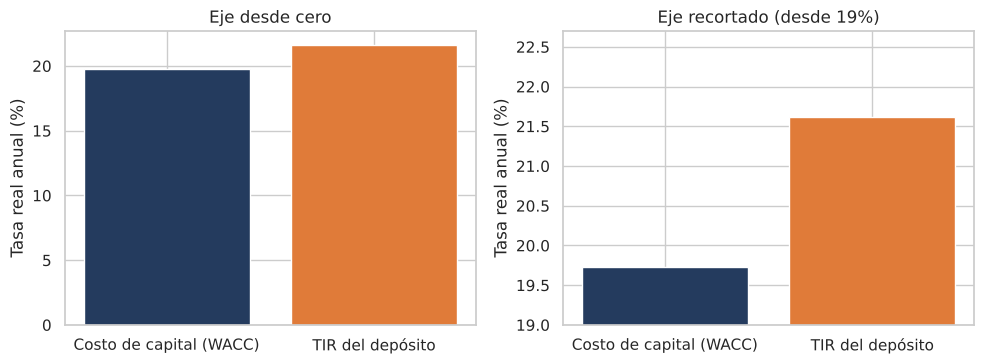

La TIR es 10% más alta que el WACC, pero en el gráfico recortado la barra parece 260% más alta.


In [40]:
barras = pd.Series({"Costo de capital (WACC)": wacc_real, "TIR del depósito": tir(flujos)}) * 100
piso = 19                                                     # el eje recortado arranca en 19%

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, minimo, titulo in [(axs[0], 0, "Eje desde cero"), (axs[1], piso, "Eje recortado (desde 19%)")]:
    ax.bar(barras.index, barras.values, color=[AZUL, NARANJA])
    ax.set_ylim(bottom=minimo)                                # acá está el truco: dónde empieza el eje
    ax.set_title(titulo)
    ax.set_ylabel("Tasa real anual (%)")
plt.tight_layout()
plt.show()

real = barras.iloc[1] / barras.iloc[0] - 1                    # cuánto más alta es la TIR, de verdad
visual = (barras.iloc[1] - piso) / (barras.iloc[0] - piso) - 1    # cuánto más alta "parece" la barra
print(f"La TIR es {real:.0%} más alta que el WACC, pero en el gráfico recortado la barra parece {visual:.0%} más alta.")

**Cómo se lee:** el dato es el mismo; la impresión, no. Con el eje desde cero se ve lo que dijo la Parte B: el depósito conviene, **por poco**. Con el eje recortado parece que conviene por goleada. En **barras** el eje arranca en cero, porque lo que se compara es la **altura**. (En un gráfico de **líneas** recortar el eje puede ser honesto, porque lo que importa es la variación.)

### G5. Lo que se acumula siempre sube

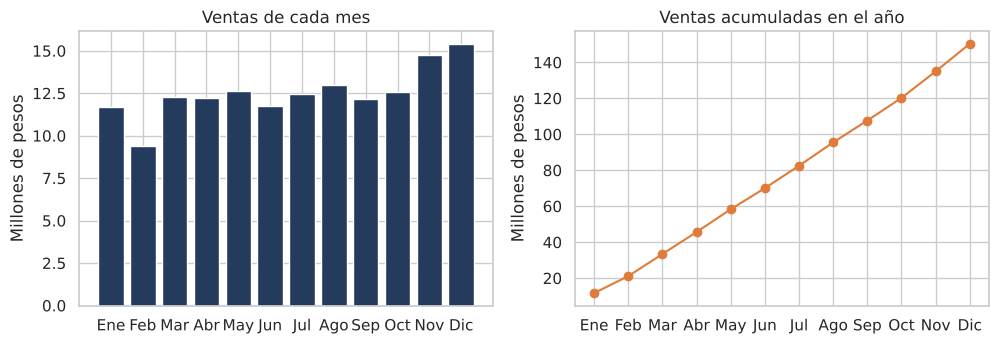

In [41]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].bar(mensual.index, mensual["ventas"] / 1e6, color=AZUL)
axs[0].set_title("Ventas de cada mes")
axs[0].set_ylabel("Millones de pesos")
axs[1].plot(mensual.index, mensual["ventas"].cumsum() / 1e6, marker="o", color=NARANJA)
axs[1].set_title("Ventas acumuladas en el año")
axs[1].set_ylabel("Millones de pesos")
plt.tight_layout()
plt.show()

**Cómo se lee:** febrero fue un mes **malo** (las ventas caen), pero la curva acumulada igual **sube**. Una curva acumulada solo puede subir (si no hay ventas negativas): por eso es la favorita de quien quiere mostrar "crecimiento". Lo que importa es la **pendiente**, y esa se ve mejor en el gráfico de cada mes. (Misma lógica que la inflación acumulada de la clase 16.)

### Checklist: antes de creerle (o mostrar) un número

| Pregunta | Dónde la vimos |
|---|---|
| ¿Qué se midió *exactamente*, y a quién? | C1 (duplicados y errores), F1 (muestra de conveniencia) |
| ¿Qué ventana de tiempo se eligió? | G1 |
| ¿Por año o en total? ¿Puntos o porcentaje? ¿Nominal o real? | G2, A4 |
| ¿Correlación o causa? ¿Hay una tercera causa? | G3, C5 |
| ¿El eje arranca en cero? ¿Es acumulado? | G4, G5 |
| ¿Qué supuestos hay detrás, y qué pasa si fallan? | E, F2 |

Las otras trampas de la clase (el promedio que nadie gana, la máquina que acierta el 99%, la paradoja de Simpson, la torta, los dibujitos, los mapas) están en [**Cómo mentir con datos y cómo darte cuenta**](https://manuelfsm03.github.io/labo-fce/mentir-con-datos/).

> **En el TP:** cada gráfico y cada conclusión tienen que poder pasar este checklist. Si el informe dice un número, un lector externo tiene que poder preguntar "¿cómo se calculó, con qué datos y qué ventana?", y encontrar la respuesta.

---
# H. La decisión: juntar las miradas

Volvemos a la pregunta de Lucía: **¿invierte en el depósito?** Armamos un tablero con lo que dijo cada parte (todos los números salen de las celdas de arriba):

In [42]:
tablero = pd.DataFrame([
    ["A. Costo de capital", "Costo de capital real (WACC)", f"{wacc_real:.1%}", "referencia"],
    ["B. Rendimiento", "VAN / TIR", f"{millones(van(flujos, R))} / {tir(flujos):.1%}", "🟢 conviene, por poco"],
    ["B. Rendimiento", "Payback descontado (de 5 años de vida)", f"{payback(vp):.1f} años", "🟡 recupera sobre el final"],
    ["D. Caja", "Caja mínima, al contado, mora 10%", millones(caja_acumulada("contado", 0.10).min()), semaforo(caja_acumulada("contado", 0.10).min()) + " casi sin colchón"],
    ["D. Caja", "Caja mínima, financiado, mora 10%", millones(caja_acumulada("financiado", 0.10).min()), semaforo(caja_acumulada("financiado", 0.10).min()) + " alcanza, ajustado"],
    ["E. Marginalidad", "Beneficio extra solo con accesorios / flujo esperado", f"{float(mejora_total) * 365 / 3.2e6:.0%} del año 1", "🟡 el resto debe venir de hogar y electrónica"],
    ["F. Riesgo", "Probabilidad de perder plata (desvío 20%)", f"{(vans < 0).mean():.0%}", "🟠 una chance en tres"],
], columns=["Parte", "Pregunta", "Resultado", "Lectura"])
tablero

,Parte,Pregunta,Resultado,Lectura
0,A. Costo de capital,Costo de capital real (WACC),19.7%,referencia
1,B. Rendimiento,VAN / TIR,"$ 0,36 M / 21.6%","🟢 conviene, por poco"
2,B. Rendimiento,Payback descontado (de 5 años de vida),4.6 años,🟡 recupera sobre el final
3,D. Caja,"Caja mínima, al contado, mora 10%","$ 2,35 M",🟠 casi sin colchón
4,D. Caja,"Caja mínima, financiado, mora 10%","$ 7,85 M","🟡 alcanza, ajustado"
5,E. Marginalidad,Beneficio extra solo con accesorios / flujo es...,35% del año 1,🟡 el resto debe venir de hogar y electrónica
6,F. Riesgo,Probabilidad de perder plata (desvío 20%),35%,🟠 una chance en tres


**¿Qué le diríamos a Lucía?** No hay una respuesta "correcta": hay una **decisión informada**. Una posible lectura:

1. **Conviene, pero ajustado.** El VAN es positivo y la TIR le gana al costo de capital, pero por poco, y se recupera tarde.
2. **No lo pagues al contado.** Al contado la caja se rompe con una mora de 28%; financiado aguanta hasta 31% (Parte D3).
3. **Vigilá la mora y los plazos de cobro.** Un cambio de proceso (cobrar más por transferencia) pesa tanto como el precio del depósito.
4. **No lo justifiques con accesorios.** Solo explican alrededor de un tercio del flujo esperado; el depósito tiene que mejorar también hogar y electrónica.
5. **Hay una chance en tres de perder plata.** Si Lucía no puede bancarse ese escenario, el depósito no es para ella, más allá del VAN.

> **La idea de la clase:** ninguna herramienta, sola, alcanza. El VAN dice si rinde, la caja dice si se puede pagar, los datos dicen qué es verdad, las integrales dicen de dónde sale el valor y la simulación dice cuánto riesgo hay.

---
# 📝 Ejercicios

Cada ejercicio usa una herramienta que **no** repetimos en el cuerpo de la clase.

**Ejercicio 1 (Parte A) - Plazo fijo vs. inflación.** Antes de pedir el préstamo, Lucía tiene **\$ 2.000.000** ociosos y piensa dejarlos **30 días** en un plazo fijo a **TNA 40%** (convención del BCRA: `TNA × 30/365`). En ese mes la inflación fue de **2,8%**. (a) ¿Cuánto retira al vencimiento? (b) ¿Cuál es la tasa **real** del mes (Fisher)? (c) Si repitiera lo mismo los 12 meses, ¿qué TEA rinde el plazo fijo y cuál es la TEA de la inflación? ¿Ganó o perdió poder de compra?

**Ejercicio 2 (Parte B) - Valor residual y TIRM.** Al final del año 5, Lucía podría vender los equipos del depósito por **\$ 2 millones** (valor residual, que se suma al flujo del año 5). Además, los flujos intermedios no se pueden reinvertir al 19,7%: solo consigue **15% real**. Calculá el **VAN**, la **TIR** y la **TIRM** (clase 13) del proyecto con valor residual. *TIRM $=(VF_{\text{flujos positivos}} / VP_{\text{inversión}})^{1/n}-1$, con los flujos positivos capitalizados hasta el año 5 a la tasa de reinversión.* ¿Cuál de las tres medidas depende más de la tasa de reinversión?

**Ejercicio 3 (Parte D) - ¿Cuándo comprarlo?** La función `caja_acumulada` usa la variable `MES_COMPRA` (hoy, marzo). ¿Qué pasa si Lucía compra el depósito en **octubre** (posición 9), justo antes del Black Friday y el Cyber Monday? Con **mora de 20%**, compará la caja mínima y el semáforo (financiado y al contado) entre comprarlo en marzo y en octubre. ¿Qué se pierde al esperar? *Pista: pensá en los flujos que el depósito deja cada mes.*

**Ejercicio 4 (clases 16 y 19) - Desigualdad entre clientes.** Simulá el gasto anual de **5.000 clientes** de Nodo Market (muchos gastan poco y pocos gastan muchísimo) con `rng = np.random.default_rng(11)` y `gasto_clientes = rng.lognormal(mean=np.log(60_000), sigma=0.9, size=5_000).round()`. Armá la **curva de Lorenz** (qué % del gasto acumulan los clientes más pobres, ordenados de menor a mayor gasto) y calculá el **índice de Gini** con la regla del trapecio ($Gini = 1 - 2\times$ área bajo la curva). ¿Qué % del gasto aporta la mitad de clientes que menos gasta?

**Ejercicio 5 (Parte F) - Muestreo estratificado.** Lucía puede revisar **28 días** de la exportación para estimar la demanda de accesorios. Compará, repitiendo **300 veces**: (a) 28 días **al azar**; (b) una muestra **estratificada**: 20 días de semana y 8 de fin de semana (respetando la proporción real de cada tipo de día). ¿Cuál se equivoca menos, en promedio? ¿Por qué?

**Ejercicio 6 (Parte C) - Unir tablas (`merge`).** Logística le pasó una tabla con las **tasas de devolución** por categoría, pero está incompleta: tiene **Accesorios**, **Hogar** y **Juguetes** (una categoría que Nodo Market todavía no vende) y **le falta Electrónica**. (a) Uní `ventas` con esa tabla usando `inner`, `left`, `right` y `outer`: ¿cuántas filas quedan con cada una y qué pasa con Electrónica y con Juguetes? (b) ¿Qué `join` usarías para calcular el **ingreso neto de devoluciones** de todo el negocio? Calculalo, completando las tasas que faltan con el promedio de las que sí están.

In [43]:
# Ejercicio 1 - tu respuesta acá

In [44]:
# Ejercicio 2 - tu respuesta acá

In [45]:
# Ejercicio 3 - tu respuesta acá

In [46]:
# Ejercicio 4 - tu respuesta acá

In [47]:
# Ejercicio 5 - tu respuesta acá

In [48]:
# Ejercicio 6 - tu respuesta acá

---
## Soluciones

Intentalo antes de mirar.

In [49]:
# Solución ejercicio 1
capital, TNA_PF, DIAS, INFLACION_MES = 2_000_000, 0.40, 30, 0.028

i_periodo = proporcion(TNA_PF, DIAS)                          # tasa del período: TNA x 30/365 (la función de la Parte A)
retira = capital * (1 + i_periodo)
i_real = (1 + i_periodo) / (1 + INFLACION_MES) - 1            # Fisher

tea_pf = (1 + i_periodo) ** (365 / DIAS) - 1                  # TEA renovando cada 30 días
tea_inflacion = (1 + INFLACION_MES) ** 12 - 1                 # inflación anual si todos los meses fueran iguales

print(f"Retira {pesos(retira)} (intereses {pesos(retira - capital)})")
print(f"Tasa real del mes: {i_real:+.2%}")
print(f"TEA del plazo fijo: {tea_pf:.1%} | TEA de la inflación: {tea_inflacion:.1%}")
print("Ganó poder de compra" if i_real > 0 else "Perdió poder de compra", "(por poco: el plazo fijo apenas le gana a la inflación)")

Retira $ 2.065.753 (intereses $ 65.753)
Tasa real del mes: +0.47%
TEA del plazo fijo: 48.2% | TEA de la inflación: 39.3%
Ganó poder de compra (por poco: el plazo fijo apenas le gana a la inflación)


In [50]:
# Solución ejercicio 2
flujos_res = flujos.astype(float).copy()
flujos_res[5] += 2_000_000                                    # el valor residual se suma al flujo del año 5
TASA_REINV = 0.15

# TIRM = (VF de los flujos positivos / VP de la inversión) ^ (1/n) - 1
def tirm(fl, tasa_reinversion):
    n = len(fl) - 1
    vf_positivos = sum(f * (1 + tasa_reinversion) ** (n - t) for t, f in enumerate(fl) if f > 0)   # cada flujo capitalizado hasta el año n
    return (vf_positivos / -fl[0]) ** (1 / n) - 1

print(f"VAN con residual : {millones(van(flujos_res, R))}  (sin residual: {millones(van(flujos, R))})")
print(f"TIR con residual : {tir(flujos_res):.1%}")
for tasa in [0.15, 0.20, 0.25]:
    print(f"TIRM reinvirtiendo al {tasa:.0%}: {tirm(flujos_res, tasa):.1%}")
print("La TIRM cambia con la tasa de reinversión; la TIR supone implícitamente que se reinvierte a la propia TIR y no depende de ella.")

VAN con residual : $ 1,18 M  (sin residual: $ 0,36 M)
TIR con residual : 25.3%
TIRM reinvirtiendo al 15%: 20.5%
TIRM reinvirtiendo al 20%: 22.8%
TIRM reinvirtiendo al 25%: 25.2%
La TIRM cambia con la tasa de reinversión; la TIR supone implícitamente que se reinvierte a la propia TIR y no depende de ella.


In [51]:
# Solución ejercicio 3
resultados = []
for mes, nombre in [(2, "Marzo"), (9, "Octubre")]:
    MES_COMPRA = mes                                          # cambiamos la variable global que usa la función
    for proyecto in ["contado", "financiado"]:
        minima = caja_acumulada(proyecto, mora=0.20).min()
        resultados.append({"Compra en": nombre, "Forma de pago": proyecto, "Caja mínima (M)": minima / 1e6, "Semáforo": semaforo(minima)})
MES_COMPRA = 2                                                # volvemos al valor original (marzo)

display(pd.DataFrame(resultados).round(2))

perdido = FLUJO_DEPOSITO_ANUAL / 12 * (9 - 2)                 # los 7 meses de flujo que el depósito no deja si se espera a octubre
print(f"Esperar a octubre cuesta {pesos(perdido)} de flujos que el depósito no genera, y la caja mínima casi no mejora: el problema no es el mes, es pagar 9 millones de golpe.")

,Compra en,Forma de pago,Caja mínima (M),Semáforo
0,Marzo,contado,1.03,🟠
1,Marzo,financiado,5.55,🟠
2,Octubre,contado,2.15,🟠
3,Octubre,financiado,7.65,🟡


Esperar a octubre cuesta $ 1.866.667 de flujos que el depósito no genera, y la caja mínima casi no mejora: el problema no es el mes, es pagar 9 millones de golpe.


Gini: 0.47
La mitad de clientes que menos gasta aporta el 19% del gasto total


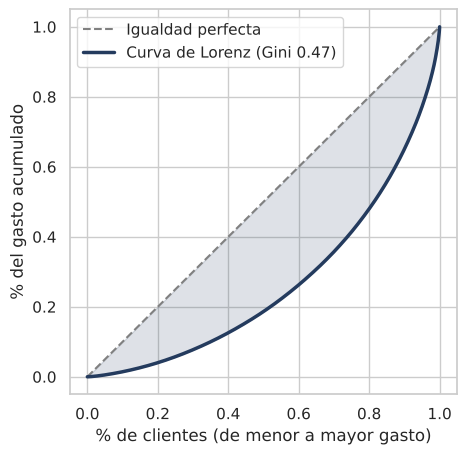

In [52]:
# Solución ejercicio 4
rng = np.random.default_rng(11)
gasto_clientes = rng.lognormal(mean=np.log(60_000), sigma=0.9, size=5_000).round()   # 5.000 clientes: muchos gastan poco, pocos muchísimo

orden = np.sort(gasto_clientes)                               # de menor a mayor gasto
p = np.arange(0, len(orden) + 1) / len(orden)                 # % de clientes: 0, 1/5000, ..., 1
L = np.r_[0, orden.cumsum() / orden.sum()]                    # % del gasto acumulado (curva de Lorenz)

gini = 1 - 2 * trapecio(L, p)                                 # 1 - 2 x área bajo la curva (regla del trapecio, clase 16)
mitad_pobre = L[len(orden) // 2]

print(f"Gini: {gini:.2f}")
print(f"La mitad de clientes que menos gasta aporta el {mitad_pobre:.0%} del gasto total")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Igualdad perfecta")
plt.plot(p, L, color=AZUL, lw=2.5, label=f"Curva de Lorenz (Gini {gini:.2f})")
plt.fill_between(p, p, L, color=AZUL, alpha=0.15)
plt.xlabel("% de clientes (de menor a mayor gasto)")
plt.ylabel("% del gasto acumulado")
plt.legend()
plt.show()

In [53]:
# Solución ejercicio 5
laborables = demanda_dia[demanda_dia.index.dayofweek < 5]     # lunes a viernes
finde = demanda_dia[demanda_dia.index.dayofweek >= 5]         # sábados y domingos
peso_lab = len(laborables) / len(demanda_dia)                 # proporción real de días de semana (~5/7)

al_azar, estratificada = [], []
for i in range(300):
    al_azar.append(demanda_dia.sample(28, random_state=i).mean())
    # estratificada: 20 días de semana y 8 de fin de semana, ponderados por su peso real en el año
    estratificada.append(peso_lab * laborables.sample(20, random_state=i).mean() + (1 - peso_lab) * finde.sample(8, random_state=i).mean())

print(f"Error promedio al azar       : {np.mean(np.abs(np.array(al_azar) - verdad)):.2f} unidades")
print(f"Error promedio estratificada : {np.mean(np.abs(np.array(estratificada) - verdad)):.2f} unidades")
print("La estratificada se equivoca menos: elimina la variación que viene de 'cuántos fines de semana cayeron por casualidad en la muestra'.")

Error promedio al azar       : 2.06 unidades
Error promedio estratificada : 1.75 unidades
La estratificada se equivoca menos: elimina la variación que viene de 'cuántos fines de semana cayeron por casualidad en la muestra'.


In [54]:
# Solución ejercicio 6
# La tabla incompleta: le falta Electrónica y tiene una categoría que Nodo Market no vende (Juguetes)
devoluciones = pd.DataFrame({"producto": ["Accesorios", "Hogar", "Juguetes"], "tasa_devolucion": [0.03, 0.06, 0.08]})

# (a) Los cuatro tipos de join
print(f"ventas tiene {len(ventas)} filas\n")
for como in ["inner", "left", "right", "outer"]:
    unido = ventas.merge(devoluciones, on="producto", how=como)
    sin_tasa = unido["tasa_devolucion"].isnull().sum()
    print(f"{como:6s}: {len(unido):5d} filas | filas sin tasa: {sin_tasa:4d} | categorías: {sorted(unido['producto'].unique())}")

# (b) Para el ingreso de TODO el negocio: LEFT (conserva todas las ventas, aunque falte la tasa)
neto = ventas.merge(devoluciones, on="producto", how="left")
neto["tasa_devolucion"] = neto["tasa_devolucion"].fillna(devoluciones["tasa_devolucion"].mean())    # completamos con el promedio
neto["ingreso_neto"] = neto["ingreso"] * (1 - neto["tasa_devolucion"])
print(f"\nIngreso bruto: {pesos(neto['ingreso'].sum())} | Ingreso neto de devoluciones: {pesos(neto['ingreso_neto'].sum())}")

inner = ventas.merge(devoluciones, on="producto", how="inner")
print(f"Con inner se pierde Electrónica y el ingreso queda en {pesos(inner['ingreso'].sum())}: ¡{1 - inner['ingreso'].sum() / ventas['ingreso'].sum():.0%} del negocio desaparece sin avisar!")

ventas tiene 2190 filas

inner :  1460 filas | filas sin tasa:    0 | categorías: ['Accesorios', 'Hogar']
left  :  2190 filas | filas sin tasa:  730 | categorías: ['Accesorios', 'Electrónica', 'Hogar']
right :  1461 filas | filas sin tasa:    0 | categorías: ['Accesorios', 'Hogar', 'Juguetes']
outer :  2191 filas | filas sin tasa:  730 | categorías: ['Accesorios', 'Electrónica', 'Hogar', 'Juguetes']

Ingreso bruto: $ 150.332.000 | Ingreso neto de devoluciones: $ 142.160.120
Con inner se pierde Electrónica y el ingreso queda en $ 93.668.000: ¡38% del negocio desaparece sin avisar!


---
# 🧭 Para llevarse

| Quiero... | En Python | Clase |
|---|---|---|
| comparar préstamos: costo total anual | `TEM total = TNA/12 * (1 + IVA) + seguro + comisión`; `CFTEA = (1 + TEM total) ** 12 - 1` | 13 |
| la cuota de un préstamo | `prestamo / ((1 + i) ** -np.arange(1, n + 1)).sum()` | 13 |
| pasar una tasa efectiva de un plazo a otro | `(1 + i) ** (t2 / t1) - 1` | 13 |
| pasar de nominal a real | `(1 + i) / (1 + inflación) - 1` | 13 |
| saber si un proyecto crea valor | `van(flujos, tasa)`, `tir(flujos)` | 13, 14 |
| saber cuándo recupero la plata | `payback(...)` (simple y descontado) | 14 |
| limpiar una base | `drop_duplicates()`, `fillna(...)`, `isnull().sum()` | 15.5 |
| unir tablas (y no perder filas sin avisar) | `df.merge(otra, on="col", how="inner" / "left" / "right" / "outer")` | 15.5 |
| resumir por grupos | `df.groupby("col").agg(...)` | 15.5 |
| una regresión | `LinearRegression().fit(X, y)` | 15.5 |
| armar un flujo de caja y mirar la mora | función `caja_acumulada(proyecto, mora)` | 15 |
| pasar de lo marginal a lo acumulado | `sp.integrate(IMg - CMg, (q, 0, q_opt))` | 16 |
| números al azar, repetibles | `rng = np.random.default_rng(42)` | 19 |
| no engañarme con un número | ¿por año o total?, ¿puntos o %?, ¿nominal o real?, la serie completa, buscar la tercera causa, eje desde cero | "Cómo mentir con datos" |
| una muestra al azar | `df.sample(n, random_state=1)` | 19 |
| simular miles de futuros | un `for` con `rng.normal(esperado, desvío)` | 19 |

**Seis ideas:**
1. **Una decisión se mira de varias maneras:** rendimiento (VAN), liquidez (caja), evidencia (datos), valor marginal (integrales) y riesgo (simulación).
2. **Pesos corrientes con tasa nominal; pesos constantes con tasa real.** Nunca mezclar.
3. **Rentable no es lo mismo que líquido:** un proyecto con VAN positivo puede dejar sin caja.
4. **Los datos reales vienen sucios:** mirar, limpiar y justificar cada decisión *antes* de analizar.
5. **Una simulación vale lo que valen sus supuestos:** y el sesgo no se arregla con más datos.
6. **Se puede mentir con datos verdaderos:** ventanas elegidas a dedo, porcentajes, correlaciones sin causa y ejes recortados. Antes de creerle (o mostrar) un número, pasalo por el checklist de la Parte G.

---
## 🎓 Cómo se conecta con el TP grupal

El TP pide **un análisis completo de datos propios**. Esta clase es un ejemplo de ese recorrido:

| El TP pide... | En esta clase |
|---|---|
| **3.1** Carga y exploración (`head`, `tail`, `dtypes`, nulos, duplicados, `describe`) | Parte C1 |
| **3.2** Pregunta de investigación (qué, por qué, qué respuesta) | La pregunta de Lucía: *¿invierte en el depósito?* (y las sub-preguntas de la tabla inicial) |
| **3.3** Dos transformaciones justificadas y dos `groupby` interpretados | Partes C2, C3 y C4 (y el `merge` con sus variantes en el Ejercicio 6) |
| **3.4** Tres gráficos de tipos distintos, con título, ejes e interpretación | Parte C5 (barras, serie temporal, dispersión con regresión) |
| Honestidad al mostrar resultados | Parte G: checklist para no engañar (ni engañarse) con ventanas, porcentajes, correlaciones y ejes |
| Supuestos explícitos y riesgo | Parte F: un análisis serio dice **qué supone** y **cuánto cambia el resultado** si el supuesto falla |

> **Un consejo:** antes de empezar el análisis de su dataset, escriban **la pregunta** y **la decisión** que esa pregunta ilumina, como hicimos acá con el depósito. Todo lo demás (limpiar, agrupar, graficar, simular) se ordena alrededor de esa pregunta.